# §8 Fairness and the 3 × 3 Label Matrix

§5 showed that the label and one feature are measured unevenly across groups: self-report misses the 152
undiagnosed people, who are more often uninsured or without a usual place of care, and BMI under-reads adiposity in
Asian adults. This section checks whether those biases **carry over into the model**:

1. **Group audit** (§8.1–§8.5) – error rates of arm S by race, insurance, access, income and sex at one threshold, with
   bootstrap intervals, small-cell suppression and a permutation baseline.
2. **3 × 3 label matrix** (§8.6–§8.7, pre-registered H3) – one pipeline trained on three labels and scored on three
   kinds of diabetes, plus an access-proxy audit arm.
3. **Mitigation** (§8.8–§8.12) – reweighing, the WHtR fix (P14-b), group thresholds, the trade-off and calibration.

Everything uses the out-of-fold predictions of the **training part** on the §7 folds; the hold-out is not read. Race,
insurance and access never enter a prediction model (§1 availability rule): they are audit variables only.

In [1]:
import sys, pathlib
_here = pathlib.Path.cwd()
ROOT = next(p for p in [_here, *_here.parents] if (p / "src" / "config.py").exists())
sys.path.insert(0, str(ROOT))
from src import config as C, plots, results_io as R

import json, os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import nhanes_io as io, labels as L, prep as P, evalkit as ek, survey as SV, fairness as F

from IPython.display import display
pd.set_option("display.width", 150, "display.max_columns", 30, "display.max_colwidth", 60)


def show(df, digits=3):
    """Display a table as HTML (long text wraps; keeps the text output narrow)."""
    display(df.style.hide(axis="index").format(precision=digits, na_rep="")
            .set_properties(**{"text-align": "left", "white-space": "normal"}))

OUT = C.RESULTS_DIR / "S8"
OUT.mkdir(parents=True, exist_ok=True)
os.environ.setdefault("PYTHONWARNINGS", "ignore::UserWarning")
N_JOBS = min(12, max(1, (os.cpu_count() or 2) - 2))
N_PERM_GROUP = 200          # group-label permutations (process doc S8 step 2)
SPEC = C.SPEC_FIXED
GAP, GAP_SUB = C.SESOI["group_tpr_gap"], C.SESOI["group_tpr_gap_substantive"]
AUC_SESOI = C.SESOI["roc_auc"]
T_START = time.time()
S8 = {"mode": C.NB_MODE, "cv": f"{C.CV_SPLITS}x{C.CV_REPEATS}", "n_boot": C.N_BOOT, "n_perm_group": N_PERM_GROUP,
      "spec": SPEC}
print(f"mode {C.NB_MODE}: {C.CV_SPLITS}x{C.CV_REPEATS} CV, B = {C.N_BOOT}, {N_PERM_GROUP} group permutations, {N_JOBS} workers")

mode FINAL: 5x5 CV, B = 1000, 200 group permutations, 12 workers


## 0 Setup
**Why.** The audit must evaluate exactly the predictions that §7 judged. The stored hold-out split and folds are
re-verified, the OOF file is checked against the folds, and one fold of arm S is refitted to prove that a refit
reproduces the stored predictions, so the new arms below (other labels, reweighing) are paired with S on equal terms.

In [2]:
raw = P.raw_cohort()
clean = L.add_labels(io.build_cohort())
assert (raw["SEQN"].to_numpy() == clean["SEQN"].to_numpy()).all()
tr, te = ek.make_holdout(clean)
raw_tr = raw.iloc[tr].reset_index(drop=True)
cl = clean.iloc[tr].reset_index(drop=True)
X1 = P.raw_feature_frame(raw_tr, 1)
y = cl["L_comb"].to_numpy().astype(int)
esc = cl["in_escreen"].eq(1).to_numpy()
y_esc = cl["y_escreen"].fillna(0).astype(int).to_numpy()
strat = cl["stratum_3x3"].astype(str).to_numpy()
folds = ek.make_folds(y, strat)
n = len(y)
n_test_fold, n_train_fold = n / C.CV_SPLITS, n - n / C.CV_SPLITS
grp = F.audit_groups(cl)
S7m = R.load_section("S7")
C0 = float(S7m["C0"]["C0"])
assert folds.hash[:16] == S7m["splits"]["folds_hash"][:16] or C.NB_MODE == "FAST"

oof_all = pd.read_parquet(C.RESULTS_DIR / "oof_predictions.parquet")
oof_all = oof_all[oof_all["repeat"] < C.CV_REPEATS]          # FAST folds = first 2 repeats of the FINAL folds
assert not set(oof_all["SEQN"]) & set(clean["SEQN"].iloc[te]) and set(oof_all["SEQN"]) <= set(cl["SEQN"])   # no hold-out row
assert (oof_all.drop_duplicates("row").set_index("row")["SEQN"].sort_index().to_numpy() == cl["SEQN"].to_numpy()).all()
OOF = {}
for (a, t, m), g in oof_all.groupby(["arm", "tier", "model"], observed=True):
    OOF[(a, int(t), m)] = g[["repeat", "fold", "row", "prob"]].astype({"prob": float}).reset_index(drop=True)
# every stored (repeat, fold) test set equals the stored fold file
s_oof = OOF[("S", 1, "lr")]
for i, (_, te_i) in enumerate(folds):
    r_, f_ = i // folds.n_splits, i % folds.n_splits
    assert np.array_equal(np.sort(s_oof.query("repeat == @r_ and fold == @f_")["row"].to_numpy()), te_i)
PM = {k: ek.mean_oof(v, n) for k, v in OOF.items()}            # repeat-averaged OOF probability per row

cfgS = P.ARMS["S"]
fpS = P.fit_params(cfgS, raw_tr)
w_svy = P.survey_weights(raw_tr)
tr0, te0 = folds[0]
m0 = P.build_pipeline(cfgS, 1, C_=C0).fit(X1.iloc[tr0], y[tr0], model__sample_weight=w_svy[tr0])
refit = m0.predict_proba(X1.iloc[te0])[:, 1]
stored = s_oof.query("repeat == 0 and fold == 0").set_index("row").loc[te0, "prob"].to_numpy()
max_dev = float(np.abs(refit - stored).max())
assert max_dev < 1e-5, max_dev
assert np.array_equal(P.training_label(raw_tr, cfgS), y)        # arm S trains on the frozen L_comb
print(f"training part {n:,} rows, {y.sum()} L_comb positives; E-SCREEN {esc.sum():,} rows, {y_esc[esc].sum()} positives")
print(f"folds {folds.n_splits}x{folds.n_repeats}, hash {folds.hash[:16]}...; C0 = {C0}; OOF runs loaded: {len(OOF)}")
print(f"refit of arm S, repeat 0 fold 0 vs stored OOF: max |dp| = {max_dev:.2e} (float32 storage)")
S8["setup"] = dict(n_train=n, n_pos=int(y.sum()), n_escreen=int(esc.sum()), n_pos_escreen=int(y_esc[esc].sum()),
                   folds_hash=folds.hash, C0=C0, refit_max_abs_diff=max_dev)

training part 4,584 rows, 777 L_comb positives; E-SCREEN 3,934 rows, 127 positives
folds 5x5, hash 0d20f8f706ebf1e1...; C0 = 0.1; OOF runs loaded: 46
refit of arm S, repeat 0 fold 0 vs stored OOF: max |dp| = 2.97e-08 (float32 storage)


**So what.** Refitting arm S reproduces the stored predictions to float32 precision, so every new arm here is a
paired comparison with the S predictions of §7. The training part holds 4,584 adults; E-SCREEN has only 127 positives.

## 1 Audit groups
**Why.** Without race or income oversampling in this cycle, several groups have only a few dozen cases. Five
attributes are audited: race (NH Asian separate, always exploratory), insurance (HIQ011), **low access** (uninsured
*or* no usual place of care, HUQ030 – the measures §5 linked to being undiagnosed), income band (PIR < 1.3 / 1.3–3.49 /
≥ 3.5 / missing) and sex; the reference is the largest or most advantaged group. NCHS small-cell rule: a group with
n < 30 or fewer than 30 positives is shown, but no verdict is drawn on its gap.

**Ecological-fallacy caveat.** A lower TPR for a group says that the model misses a larger share of that group's
cases; it says nothing about any individual's risk, nor that group membership causes the difference.

In [3]:
def pop_of(name):
    """(label vector, evaluation mask) of an evaluation population."""
    if name == "E-ALL":
        return y, np.ones(n, bool)
    if name == "E-SCREEN":
        return y_esc, esc
    raise ValueError(name)

size_rows = []
for attr in F.ATTRIBUTES:
    for lv in F.LEVELS[attr]:
        m = grp[attr].eq(lv).to_numpy()
        size_rows.append({"attribute": attr, "group": lv, "ref": lv == F.REFERENCE[attr], "n": int(m.sum()),
                          "pos_eall": int(y[m].sum()), "n_escreen": int((m & esc).sum()), "pos_escreen": int(y_esc[m & esc].sum()),
                          "status_eall": F.cell_status(int(m.sum()), int(y[m].sum())),
                          "status_escreen": F.cell_status(int((m & esc).sum()), int(y_esc[m & esc].sum()))})
    size_rows.append({"attribute": attr, "group": "(unknown)", "n": int(grp[attr].isna().sum())})
sizes = pd.DataFrame(size_rows)
sizes.to_csv(OUT / "group_sizes.csv", index=False)
show(sizes)
n_supp = {p: int((sizes[f"status_{p}"] == "suppress").sum()) for p in ("eall", "escreen")}
print(f"\nsuppressed groups (n < 30 or positives < 30): E-ALL {n_supp['eall']}, E-SCREEN {n_supp['escreen']} "
      f"of {int(sizes['status_eall'].notna().sum())}")
S8["group_sizes"] = sizes.to_dict("records")
S8["n_suppressed"] = n_supp

attribute,group,ref,n,pos_eall,n_escreen,pos_escreen,status_eall,status_escreen
race,NH White,True,2727,398.000,2392.000,63.000,present,present
race,NH Black,False,540,131.000,433.000,24.000,present,suppress
race,NH Asian,False,252,40.000,223.000,11.000,present,suppress
race,Mexican American,False,309,69.000,256.000,16.000,present,suppress
race,Other Hispanic,False,465,82.000,394.000,11.000,present,suppress
race,Other/Multi,False,291,57.000,236.000,2.000,present,suppress
race,(unknown),,0,,,,,
insurance,insured,True,4186,725.000,3571.000,110.000,present,present
insurance,uninsured,False,390,51.000,356.000,17.000,present,suppress
insurance,(unknown),,8,,,,,



suppressed groups (n < 30 or positives < 30): E-ALL 0, E-SCREEN 10 of 16


**So what.** On E-ALL every group passes the 30-positive rule, NH Asian adults with only 40 positives (exploratory).
On E-SCREEN 10 of 16 groups fall below 30 positives, so their gaps are numbers only. That is itself a governance
finding: a fairness audit of the screening use case needs more data than NHANES 2021–23 provides.

## 2 Group metrics at the fixed threshold
**Why.** Equal opportunity (Hardt et al. 2016) asks whether people *with* diabetes are found at the same rate in each
group. One threshold is fixed for everybody: specificity 0.80 on all negatives of the population (no group thresholds,
§8.10). Per group: TPR, FPR, selection rate, PPV, within-group AUC and observed-to-expected ratio (O:E). Intervals come
from a bootstrap stratified by group × label with the threshold **re-estimated in every replicate**. Arm S is
class-weighted, so its O:E is far below 1 everywhere; only O:E differences between groups are informative here
(absolute calibration: §8.12).

In [4]:
AUD = {}   # (attr, pop, tier, arms) -> (point, boot, codes, mask)

def audit(attr, pop="E-ALL", tier=1, arms=("S",), weights="simple", preds=None):
    """Run the bootstrap engine for one attribute / population / tier and a tuple of arms (paired)."""
    key = (attr, pop, tier, tuple(arms), weights)
    if key in AUD and preds is None:
        return AUD[key]
    yy, m = pop_of(pop)
    lv = F.LEVELS[attr]
    codes = F.encode(grp[attr], lv)[m]
    Pm = np.vstack([(PM[(a, tier, "lr")] if preds is None or a not in preds else preds[a])[m] for a in arms])
    point = F.boot_engine(yy[m], Pm, codes, len(lv))
    seed = ek.derive_seed(C.SEED_MASTER, "S8", attr, pop, tier, weights)
    if weights == "simple":          # label-stratified: group size and group positives fixed (TPR, FPR, EOD)
        W = F.stratified_counts(np.char.add(codes.astype(str), np.char.add("|", yy[m].astype(str))), C.N_BOOT, seed)
    elif weights == "group":         # group-stratified only: observed cases vary (O:E, calibration)
        W = F.stratified_counts(codes.astype(str), C.N_BOOT, seed)
    else:
        W = F.psu_counts(cl.loc[m, [C.STRATA, C.PSU]].reset_index(drop=True), C.N_BOOT, seed)
    boot = F.boot_engine(yy[m], Pm, codes, len(lv), W)
    out = (point, boot, codes, m)
    if preds is None:
        AUD[key] = out
    return out

def tables(pop="E-ALL", tier=1, arm="S"):
    gt, et = [], []
    for attr in F.ATTRIBUTES:
        point, boot, _, _ = audit(attr, pop, tier, (arm,))
        g = F.group_table(point, boot, F.LEVELS[attr], attribute=attr)
        e = F.eod_table(point, boot, F.LEVELS[attr], F.REFERENCE[attr], attribute=attr)
        g.insert(0, "pop", pop); g.insert(1, "tier", tier)
        e.insert(0, "pop", pop); e.insert(1, "tier", tier)
        gt.append(g); et.append(e)
    return pd.concat(gt, ignore_index=True), pd.concat(et, ignore_index=True)

t0 = time.time()
GT1, ET1 = tables("E-ALL", 1)
thr_eall = float(audit("race")[0]["thr"][0, 0])
rec_check, thr_check = ek.recall_at_specificity(y, PM[("S", 1, "lr")])
assert abs(audit("race")[0]["tpr"][0, 0].dot(audit("race")[0]["n_pos"][0, 0]) / y.sum() - rec_check) < 1e-12
cols_show = ["attribute", "group", "n", "n_pos", "tpr", "tpr_lo", "tpr_hi", "fpr", "sel", "ppv", "auc", "auc_lo", "auc_hi", "oe", "status", "flags"]
print(f"E-ALL, Tier 1, arm S: threshold {thr_eall:.4f} (specificity 0.80 on {int((y == 0).sum())} negatives); "
      f"overall TPR {rec_check:.3f}; {time.time() - t0:.1f} s")
show(GT1[cols_show], 3)

E-ALL, Tier 1, arm S: threshold 0.6381 (specificity 0.80 on 3807 negatives); overall TPR 0.672; 1.1 s


attribute,group,n,n_pos,tpr,tpr_lo,tpr_hi,fpr,sel,ppv,auc,auc_lo,auc_hi,oe,status,flags
race,NH White,2727,398,0.709,0.651,0.766,0.210,0.283,0.366,0.845,0.825,0.862,0.356,present,
race,NH Black,540,131,0.611,0.534,0.702,0.225,0.319,0.465,0.784,0.740,0.825,0.542,present,
race,NH Asian,252,40,0.525,0.375,0.700,0.127,0.190,0.438,0.856,0.805,0.904,0.497,present,ci_width>=0.30;exploratory
race,Mexican American,309,69,0.623,0.507,0.739,0.158,0.262,0.531,0.840,0.788,0.887,0.571,present,
race,Other Hispanic,465,82,0.732,0.634,0.829,0.170,0.269,0.480,0.871,0.832,0.905,0.437,present,
race,Other/Multi,291,57,0.632,0.491,0.754,0.214,0.296,0.419,0.833,0.778,0.881,0.462,present,
insurance,insured,4186,725,0.676,0.632,0.726,0.208,0.289,0.405,0.834,0.820,0.848,0.418,present,
insurance,uninsured,390,51,0.608,0.471,0.745,0.124,0.187,0.425,0.853,0.808,0.896,0.376,present,
low_access,usual access,3838,701,0.680,0.642,0.722,0.221,0.305,0.407,0.827,0.813,0.841,0.425,present,
low_access,low access,742,75,0.587,0.480,0.720,0.100,0.150,0.396,0.873,0.837,0.906,0.336,present,


**So what.** At one shared threshold the model finds about two thirds of all cases, but not evenly: the lowest TPRs
belong to NH Asian adults, the highest income band, the low-access group and the uninsured; the highest to the lowest
income band. In NH Asian, low-access and uninsured adults low TPR comes with low FPR: their whole score distribution
sits lower. Within-group AUCs overlap widely (about 0.78–0.87), so the gaps come from where each group's scores lie
relative to the shared threshold, not from worse ranking.

## 3 Gaps and permutation baseline
**Why.** A gap is only interesting if it is larger than what random group labels would produce. Two checks are
combined: (i) the equal-opportunity difference EOD = TPR_group − TPR_reference with its bootstrap CI, flagged at
|EOD| ≥ 0.05 (SESOI) and called **substantive** only if |EOD| ≥ 0.10 *and* its CI excludes 0; (ii) a group-label
permutation null: group labels are shuffled 200 times (sizes kept, threshold fixed) and the observed max |EOD| over
the reportable groups is compared with the null distribution of that maximum. The maximum is the right statistic
because with six race groups the largest of five gaps is expected to look sizeable even by chance.

In [5]:
def permutation_block(pop="E-ALL", tier=1, arm="S", preds=None):
    rows, nulls = [], {}
    yy, m = pop_of(pop)
    for attr in F.ATTRIBUTES:
        point, boot, codes, mm = audit(attr, pop, tier, (arm,), preds=preds)
        lv = F.LEVELS[attr]
        ref = lv.index(F.REFERENCE[attr])
        ok = [g for g in range(len(lv)) if F.cell_status(int(point["n"][0, 0, g]), int(point["n_pos"][0, 0, g])) == "present"]
        p_ = (PM[(arm, tier, "lr")] if preds is None else preds[arm])[mm]
        thr = np.nextafter(point["thr"][0, 0], np.inf)        # engine: positive if p > v  <=>  p >= nextafter(v)
        if ref not in ok or len(ok) < 2:
            rows.append({"pop": pop, "tier": tier, "attribute": attr, "n_groups_eligible": len(ok) - (ref in ok),
                         "observed_max_eod": np.nan, "null_q95": np.nan, "p_value": np.nan, "note": "reference or all groups suppressed"})
            continue
        res = F.eod_permutation(yy[mm], p_, codes, len(lv), ref, thr, eligible=ok, n_perm=N_PERM_GROUP,
                                seed=ek.derive_seed(C.SEED_MASTER, "S8", "perm", attr, pop, tier))
        tp = point["tpr"][0, 0]
        assert abs(res["observed"] - max(abs(tp[g] - tp[ref]) for g in ok if g != ref)) < 1e-12
        nulls[attr] = res["null"]
        rows.append({"pop": pop, "tier": tier, "attribute": attr, "n_groups_eligible": len(ok) - 1,
                     "observed_max_eod": res["observed"], "null_mean": res["null_mean"], "null_q95": res["null_q95"],
                     "p_value": res["p_value"], "note": ""})
    return pd.DataFrame(rows), nulls

PERM1, NULL1 = permutation_block("E-ALL", 1)
print("Equal-opportunity differences, E-ALL, Tier 1 (reference in column 'ref'):")
show(ET1[["attribute", "group", "ref", "eod", "eod_lo", "eod_hi", "fpr_diff", "flag_0.05", "substantive", "verdict_status"]], 3)
print("\nPermutation null of max |EOD| (reportable groups only):")
show(PERM1, 3)
sub1 = ET1[ET1["substantive"] & ET1["verdict_status"].eq("reportable")]
print(f"\nsubstantive gaps (|EOD| >= {GAP_SUB}, CI excludes 0, reportable): {len(sub1)}")
for r_ in sub1.itertuples():
    print(f"   {r_.attribute}: {r_.group} EOD {r_.eod:+.3f}")

Equal-opportunity differences, E-ALL, Tier 1 (reference in column 'ref'):


attribute,group,ref,eod,eod_lo,eod_hi,fpr_diff,flag_0.05,substantive,verdict_status
race,NH Black,NH White,-0.098,-0.192,0.009,0.015,True,False,reportable
race,NH Asian,NH White,-0.184,-0.343,-0.014,-0.083,True,True,reportable
race,Mexican American,NH White,-0.085,-0.214,0.031,-0.052,True,False,reportable
race,Other Hispanic,NH White,0.023,-0.073,0.135,-0.040,False,False,reportable
race,Other/Multi,NH White,-0.077,-0.220,0.046,0.004,True,False,reportable
insurance,uninsured,insured,-0.068,-0.197,0.068,-0.084,True,False,reportable
low_access,low access,usual access,-0.094,-0.206,0.041,-0.121,True,False,reportable
income,PIR 1.3-3.49,PIR >= 3.5,0.099,0.018,0.197,0.097,True,False,reportable
income,PIR < 1.3,PIR >= 3.5,0.186,0.085,0.270,0.131,True,True,reportable
income,PIR missing,PIR >= 3.5,0.084,-0.044,0.216,0.097,True,False,reportable



Permutation null of max |EOD| (reportable groups only):


pop,tier,attribute,n_groups_eligible,observed_max_eod,null_mean,null_q95,p_value,note
E-ALL,1,race,5,0.184,0.100,0.164,0.035,
E-ALL,1,insurance,1,0.068,0.051,0.116,0.318,
E-ALL,1,low_access,1,0.094,0.032,0.079,0.025,
E-ALL,1,income,3,0.186,0.062,0.110,0.005,
E-ALL,1,sex,1,0.016,0.026,0.072,0.652,



substantive gaps (|EOD| >= 0.1, CI excludes 0, reportable): 2
   race: NH Asian EOD -0.184
   income: PIR < 1.3 EOD +0.186


**So what.** Three attributes have a largest gap beyond the 95th percentile of the permutation null: **race** (NH Asian,
EOD about −0.18, CI excluding 0 – substantive but exploratory, 40 positives), **income** (the lowest band found *more*
often than the highest, EOD about +0.19) and **low access** (EOD about −0.09; its own CI includes 0, so borderline).
Insurance and sex show nothing beyond chance. Race, insurance and access are not inputs, so every gap must travel
through correlated features; the next table asks which.

In [6]:
pS = PM[("S", 1, "lr")]
hitS = pS >= thr_check
dec = []
for attr in F.ATTRIBUTES:
    for lv in F.LEVELS[attr]:
        m = grp[attr].eq(lv).to_numpy() & (y == 1)
        dx = m & (cl["L_self"].to_numpy() == 1)
        ud = m & (cl["L_self"].to_numpy() == 0)
        dec.append({"attribute": attr, "group": lv, "n_pos": int(m.sum()), "share_diagnosed": dx.sum() / m.sum(),
                    "mean_age": cl.loc[m, "RIDAGEYR"].mean(), "mean_bmi": cl.loc[m, "BMXBMI"].mean(),
                    "care_trace": (cl.loc[m, "BPQ020"].eq(1) | cl.loc[m, "BPQ080"].eq(1)).mean(),
                    "tpr": hitS[m].mean(), "tpr_diagnosed": hitS[dx].mean(), "tpr_undiagnosed": hitS[ud].mean() if ud.sum() else np.nan})
DEC = pd.DataFrame(dec)
DEC.to_csv(OUT / "gap_decomposition.csv", index=False)
show(DEC, 3)
r_dx = float(np.corrcoef(DEC["share_diagnosed"], DEC["tpr"])[0, 1])
r_age = float(np.corrcoef(DEC["mean_age"], DEC["tpr"])[0, 1])
r_care = float(np.corrcoef(DEC["care_trace"], DEC["tpr"])[0, 1])
tpr_dx_all = hitS[(y == 1) & (cl["L_self"].to_numpy() == 1)].mean()
tpr_ud_all = hitS[(y == 1) & (cl["L_self"].to_numpy() == 0)].mean()
print(f"\nall positives: TPR diagnosed {tpr_dx_all:.3f} vs undiagnosed {tpr_ud_all:.3f}")
print(f"across the 16 groups, correlation of TPR with share diagnosed {r_dx:.2f}, with care-trace share {r_care:.2f}, "
      f"with mean age {r_age:.2f}")
# which inputs carry the routes? arm S refitted on the whole training part (per-SD coefficients, dummies vs base level)
fullS = P.build_pipeline(cfgS, 1, C_=C0).fit(X1, y, model__sample_weight=w_svy)
coefS = pd.Series(fullS[-1].coef_[0], index=fullS[:-1].get_feature_names_out())
route_cols = [c for c in coefS.index if c.startswith(("INDFMPIR", "DMDEDUC2", "BPQ020", "BPQ080", "BMXWAIST", "BMXHIP", "BMXBMI"))]
print("\narm S coefficients of the route variables (scaled inputs):")
display(coefS[route_cols].round(3))
S8["gap_decomposition"] = dict(table=DEC.round(4).to_dict("records"), tpr_diagnosed=tpr_dx_all, tpr_undiagnosed=tpr_ud_all,
                               r_tpr_share_diagnosed=r_dx, r_tpr_care_trace=r_care, r_tpr_mean_age=r_age,
                               route_coefficients=coefS[route_cols].round(4).to_dict())

attribute,group,n_pos,share_diagnosed,mean_age,mean_bmi,care_trace,tpr,tpr_diagnosed,tpr_undiagnosed
race,NH White,398,0.842,64.455,34.031,0.897,0.709,0.713,0.683
race,NH Black,131,0.817,58.405,34.682,0.802,0.611,0.682,0.292
race,NH Asian,40,0.725,64.550,26.441,0.800,0.525,0.621,0.273
race,Mexican American,69,0.768,59.087,32.419,0.754,0.623,0.698,0.375
race,Other Hispanic,82,0.866,62.293,31.742,0.927,0.732,0.761,0.545
race,Other/Multi,57,0.965,62.649,33.933,0.877,0.632,0.636,0.500
insurance,insured,725,0.848,63.301,33.318,0.877,0.676,0.701,0.536
insurance,uninsured,51,0.667,52.529,34.120,0.686,0.608,0.706,0.412
low_access,usual access,701,0.853,63.395,33.296,0.877,0.680,0.702,0.553
low_access,low access,75,0.680,55.093,34.064,0.747,0.587,0.686,0.375



all positives: TPR diagnosed 0.702 vs undiagnosed 0.520
across the 16 groups, correlation of TPR with share diagnosed 0.53, with care-trace share 0.63, with mean age 0.22



arm S coefficients of the route variables (scaled inputs):


INDFMPIR           -0.259
BMXBMI_sp0         -0.073
BMXBMI_sp1         -0.190
BMXBMI_sp2         -0.252
BMXBMI_sp3          0.349
BMXBMI_sp4         -0.000
BMXWAIST            0.622
BMXHIP             -0.815
INDFMPIR_missing    0.019
BMXWAIST_missing    0.131
DMDEDUC2_1.0        0.267
DMDEDUC2_2.0        0.165
DMDEDUC2_3.0       -0.074
DMDEDUC2_4.0       -0.070
DMDEDUC2_5.0       -0.315
BPQ020_1.0          0.348
BPQ020_2.0         -0.375
BPQ080_1.0          0.391
BPQ080_2.0         -0.418
dtype: float64

**So what.** Three routes produce the gaps:

* **Label route.** Diagnosed cases are found far more often than undiagnosed ones (TPR about 0.70 vs 0.52, printed),
  and a group's TPR rises with its share of diagnosed cases with care traces – the access imprint of §5, reproduced.
* **Measurement route.** NH Asian cases are as old as White cases but much leaner (mean BMI about 26 vs 34); BMI and
  waist push their scores down, so they are missed more even when diagnosed.
* **Direct route.** Income has a negative and low education a positive coefficient: the model uses SES as a risk
  marker, which explains the income gaps.

The race and access gaps are mostly **label and measurement bias transmitted through the features**, so reweighing
is unlikely to remove them, while WHtR targets one route directly (§8.8–§8.9).

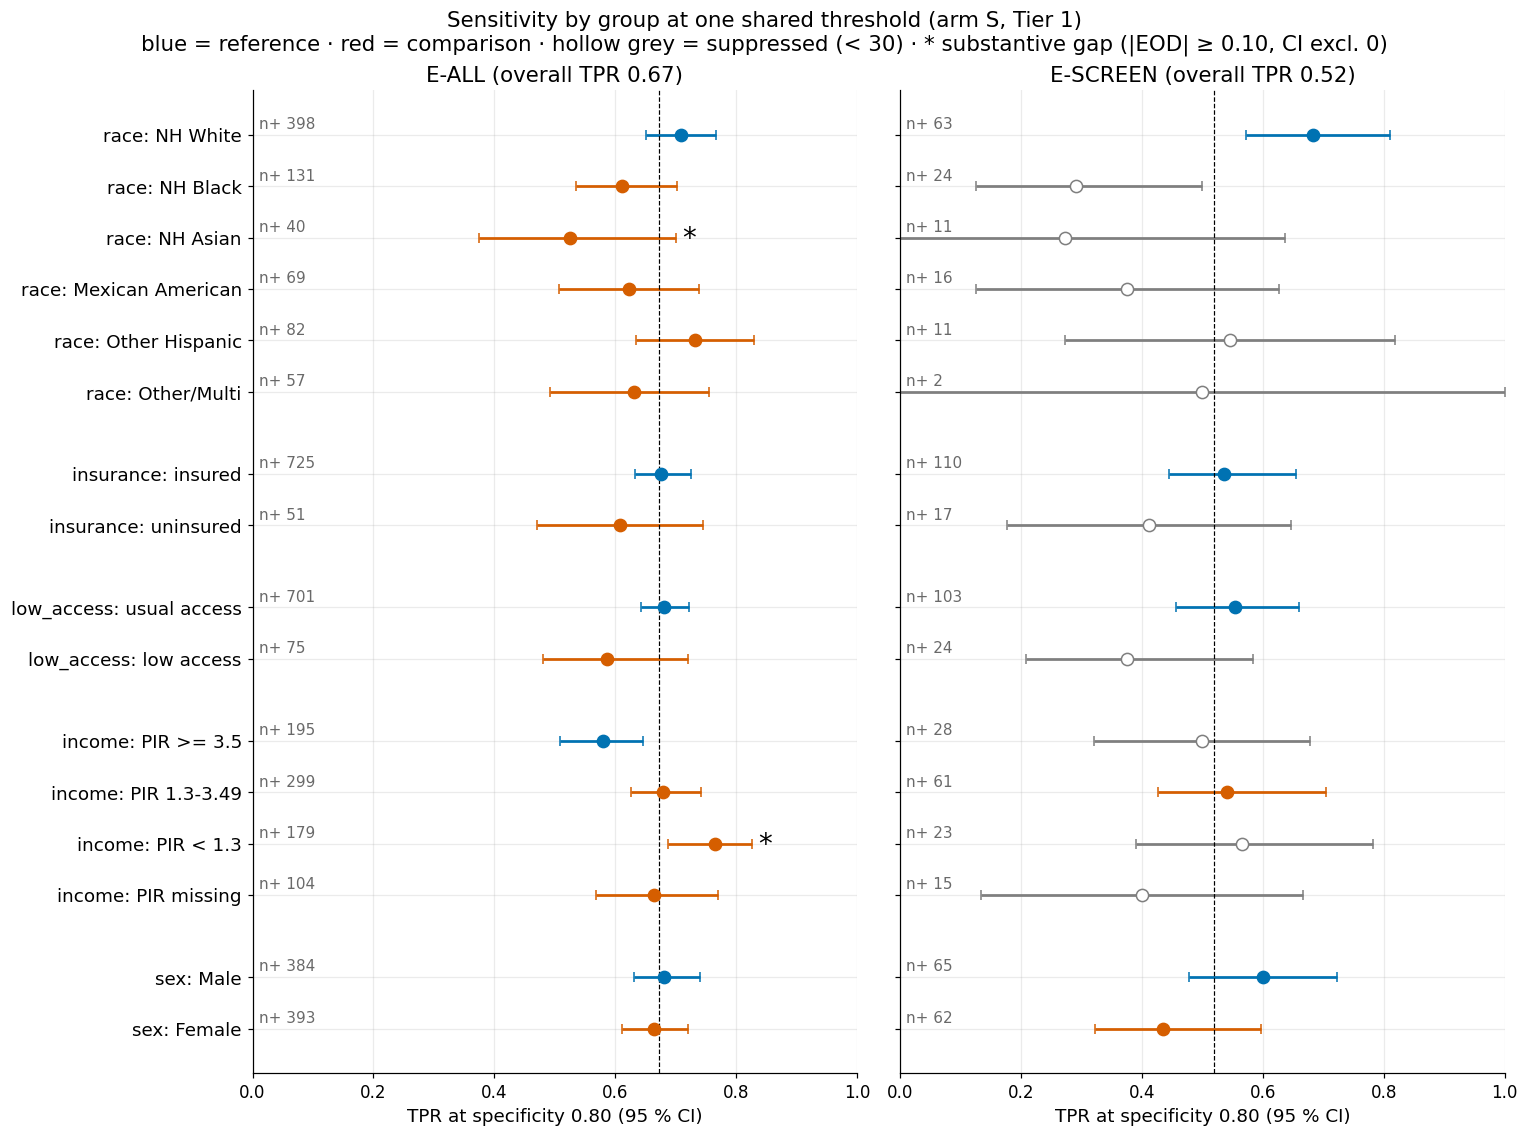

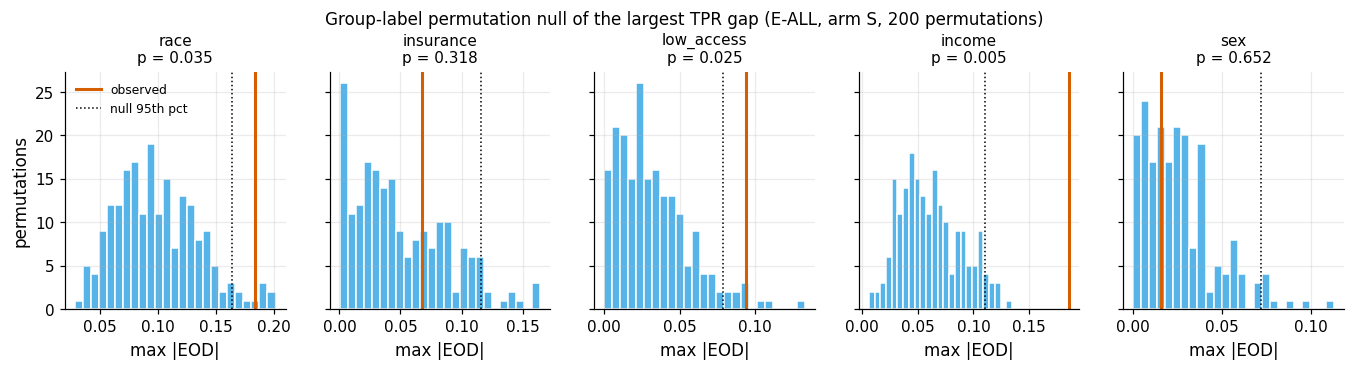

In [7]:
plots.set_style()
def tpr_panel(ax, GT, ET, title, overall):
    """Point-range of group TPRs; returns y labels (attribute: group)."""
    ylabels, ypos, k = [], [], 0
    for attr in F.ATTRIBUTES:
        g = GT[GT["attribute"] == attr]
        for _, r in g.iterrows():
            sup = r["status"] == "suppress"
            col = C.OKABE_ITO["grey"] if sup else (C.OKABE_ITO["blue"] if r["group"] == F.REFERENCE[attr] else C.OKABE_ITO["vermillion"])
            ax.errorbar(r["tpr"], -k, xerr=[[r["tpr"] - r["tpr_lo"]], [r["tpr_hi"] - r["tpr"]]], fmt="o",
                        color=col, mfc="white" if sup else col, capsize=3, ms=8, lw=1.8)
            e = ET[(ET["attribute"] == attr) & (ET["group"] == r["group"])]
            if len(e) and bool(e["substantive"].iloc[0]) and e["verdict_status"].iloc[0] == "reportable":
                ax.annotate("*", (r["tpr_hi"], -k), xytext=(4, -6), textcoords="offset points", fontsize=18, color="black")
            ax.annotate(f"n+ {int(r['n_pos'])}", (0.01, -k), xytext=(0, 4), textcoords="offset points", fontsize=10, color="dimgrey")
            ylabels.append(f"{attr}: {r['group']}")
            ypos.append(-k)
            k += 1
        k += 0.6
    ax.axvline(overall, color="black", lw=0.8, ls="--")
    ax.set_yticks(ypos); ax.set_yticklabels(ylabels, fontsize=12)
    ax.tick_params(axis="x", labelsize=11)
    ax.set_xlabel("TPR at specificity 0.80 (95 % CI)", fontsize=12)
    ax.set_title(title, fontsize=14)
    ax.set_xlim(0, 1)

# E-SCREEN tables are needed for the right panel (computed in §8.4, re-used there)
GTs, ETs = tables("E-SCREEN", 1)
rec_s, _ = ek.recall_at_specificity(y_esc[esc], PM[("S", 1, "lr")][esc])
fig, axes = plt.subplots(1, 2, figsize=(14, 10.5))
tpr_panel(axes[1], GTs, ETs, f"E-SCREEN (overall TPR {rec_s:.2f})", rec_s)
axes[1].tick_params(labelleft=False)
tpr_panel(axes[0], GT1, ET1, f"E-ALL (overall TPR {rec_check:.2f})", rec_check)
fig.suptitle("Sensitivity by group at one shared threshold (arm S, Tier 1)\n"
             "blue = reference · red = comparison · hollow grey = suppressed (< 30) · * substantive gap (|EOD| ≥ 0.10, CI excl. 0)", fontsize=14)
fig.tight_layout()
f81 = plots.savefig(fig, "S8_group_tpr", caption="F8-1. TPR at specificity 0.80 by audit group for arm S (Tier 1) on E-ALL "
                    "and E-SCREEN, stratified bootstrap 95 % CI with the threshold re-estimated per replicate; dashed line = "
                    "overall TPR; hollow grey markers are suppressed cells (n < 30 or fewer than 30 positives).")
plt.show()

fig, axes = plt.subplots(1, len(F.ATTRIBUTES), figsize=(15, 2.8), sharey=True)
for ax, attr in zip(axes, F.ATTRIBUTES):
    row = PERM1.set_index("attribute").loc[attr]
    if attr in NULL1:
        ax.hist(NULL1[attr], bins=25, color=C.OKABE_ITO["sky"], edgecolor="white")
        ax.axvline(row["observed_max_eod"], color=C.OKABE_ITO["vermillion"], lw=2, label="observed")
        ax.axvline(row["null_q95"], color="black", ls=":", lw=1, label="null 95th pct")
        ax.set_title(f"{attr}\np = {row['p_value']:.3f}", fontsize=10)
    ax.set_xlabel("max |EOD|")
axes[0].set_ylabel("permutations"); axes[0].legend(fontsize=8)
fig.suptitle("Group-label permutation null of the largest TPR gap (E-ALL, arm S, 200 permutations)", fontsize=11, y=1.08)
f81b = plots.savefig(fig, "S8_permutation_null", caption="F8-1b. Null distribution of max |TPR_g - TPR_ref| over the reportable "
                     "groups when group labels are permuted 200 times (threshold fixed), with the observed value (red) "
                     "and the null 95th percentile (dotted). E-ALL, arm S, Tier 1.")
plt.show()
S8["group_metrics_eall_t1"] = GT1.round(5).to_dict("records")
S8["eod_eall_t1"] = ET1.round(5).to_dict("records")
S8["permutation_eall_t1"] = PERM1.round(5).to_dict("records")
S8["threshold_eall_t1"] = thr_eall
S8["overall_tpr_eall_t1"] = rec_check

**So what.** The left panel is the audit in one picture: NH Asian adults and the highest income band fall clearly
below the overall TPR, the lowest income band lies above it; on E-SCREEN almost every group is suppressed. In the
permutation panel the observed maximum gap lies beyond the null's 95th percentile for race, income and low access, and
inside it for insurance and sex.

## 4 E-SCREEN
**Why.** The same audit on the use-case population (specificity 0.80 on E-SCREEN negatives; read in §8.11).

In [8]:
PERMs, NULLs = permutation_block("E-SCREEN", 1)
print(f"E-SCREEN, Tier 1, arm S: overall TPR {rec_s:.3f}")
show(GTs[cols_show], 3)
print()
show(ETs[["attribute", "group", "ref", "eod", "eod_lo", "eod_hi", "flag_0.05", "substantive", "verdict_status"]], 3)
print()
show(PERMs, 3)
rep_s = ETs[ETs["verdict_status"].eq("reportable")]
print(f"\nreportable E-SCREEN gaps: {len(rep_s)} of {len(ETs)}; substantive among them: {int(rep_s['substantive'].sum())}")
S8["group_metrics_escreen_t1"] = GTs.round(5).to_dict("records")
S8["eod_escreen_t1"] = ETs.round(5).to_dict("records")
S8["permutation_escreen_t1"] = PERMs.round(5).to_dict("records")
S8["overall_tpr_escreen_t1"] = rec_s

E-SCREEN, Tier 1, arm S: overall TPR 0.520


attribute,group,n,n_pos,tpr,tpr_lo,tpr_hi,fpr,sel,ppv,auc,auc_lo,auc_hi,oe,status,flags
race,NH White,2392,63,0.683,0.571,0.810,0.210,0.222,0.081,0.831,0.792,0.866,0.072,present,
race,NH Black,433,24,0.292,0.125,0.500,0.225,0.229,0.071,0.644,0.562,0.729,0.145,suppress,n_pos<30;ci_width>=0.30
race,NH Asian,223,11,0.273,0.000,0.636,0.127,0.135,0.100,0.809,0.703,0.900,0.179,suppress,n_pos<30;ci_width>=0.30;exploratory
race,Mexican American,256,16,0.375,0.125,0.627,0.158,0.172,0.136,0.761,0.663,0.848,0.193,suppress,n_pos<30;ci_width>=0.30
race,Other Hispanic,394,11,0.545,0.273,0.818,0.170,0.180,0.085,0.828,0.740,0.916,0.082,suppress,n_pos<30;ci_width>=0.30
race,Other/Multi,236,2,0.500,0.000,1.000,0.214,0.216,0.020,0.848,0.671,1.000,0.024,suppress,n_pos<30;ci_width>=0.30
insurance,insured,3571,110,0.536,0.445,0.655,0.208,0.218,0.076,0.787,0.751,0.819,0.085,present,
insurance,uninsured,356,17,0.412,0.176,0.647,0.124,0.138,0.143,0.775,0.697,0.848,0.153,suppress,n_pos<30;ci_width>=0.30
low_access,usual access,3240,103,0.553,0.456,0.660,0.221,0.232,0.076,0.778,0.740,0.816,0.085,present,
low_access,low access,691,24,0.375,0.208,0.583,0.100,0.110,0.118,0.826,0.773,0.877,0.128,suppress,n_pos<30;ci_width>=0.30


attribute,group,ref,eod,eod_lo,eod_hi,flag_0.05,substantive,verdict_status
race,NH Black,NH White,-0.391,-0.585,-0.171,True,True,suppressed
race,NH Asian,NH White,-0.410,-0.683,-0.062,True,True,suppressed
race,Mexican American,NH White,-0.308,-0.529,-0.026,True,True,suppressed
race,Other Hispanic,NH White,-0.137,-0.442,0.179,True,False,suppressed
race,Other/Multi,NH White,-0.183,-0.762,0.397,True,False,suppressed
insurance,uninsured,insured,-0.125,-0.396,0.124,True,False,suppressed
low_access,low access,usual access,-0.178,-0.381,0.044,True,False,suppressed
income,PIR 1.3-3.49,PIR >= 3.5,0.041,-0.160,0.285,False,False,suppressed
income,PIR < 1.3,PIR >= 3.5,0.065,-0.224,0.346,True,False,suppressed
income,PIR missing,PIR >= 3.5,-0.100,-0.407,0.207,True,False,suppressed


pop,tier,attribute,n_groups_eligible,observed_max_eod,null_q95,p_value,note,null_mean
E-SCREEN,1,race,0,,,,reference or all groups suppressed,
E-SCREEN,1,insurance,0,,,,reference or all groups suppressed,
E-SCREEN,1,low_access,0,,,,reference or all groups suppressed,
E-SCREEN,1,income,1,,,,reference or all groups suppressed,
E-SCREEN,1,sex,1,0.165,0.180,0.085,,0.073



reportable E-SCREEN gaps: 1 of 11; substantive among them: 0


## 5 Tier 2 summary
**Why.** Does adding total and HDL cholesterol (Tier 2) change the gaps? (read in §8.11)

In [9]:
GT2, ET2 = tables("E-ALL", 2)
PERM2, _ = permutation_block("E-ALL", 2)
cmp_t = (ET1.set_index(["attribute", "group"])[["eod", "eod_lo", "eod_hi", "verdict_status"]]
         .join(ET2.set_index(["attribute", "group"])[["eod", "eod_lo", "eod_hi"]], rsuffix="_t2"))
cmp_t["delta_t2_t1"] = cmp_t["eod_t2"] - cmp_t["eod"]
display(cmp_t.round(3))
summ = PERM1.set_index("attribute")[["observed_max_eod", "p_value"]].join(
    PERM2.set_index("attribute")[["observed_max_eod", "p_value"]], rsuffix="_t2")
print("\nmax |EOD| (reportable groups) and permutation p, Tier 1 vs Tier 2:")
display(summ.round(3))
max_shift = float(cmp_t["delta_t2_t1"].abs().max())
print(f"largest change of any EOD from Tier 1 to Tier 2: {max_shift:.3f}")
S8["tier2_summary"] = dict(eod=ET2.round(5).to_dict("records"), permutation=PERM2.round(5).to_dict("records"),
                           max_abs_eod_shift=max_shift)

eod  eod_lo  eod_hi verdict_status  eod_t2  eod_lo_t2  eod_hi_t2  delta_t2_t1
attribute  group                                                                                            
race       NH Black         -0.098  -0.192   0.009     reportable  -0.065     -0.154      0.017        0.033
           NH Asian         -0.184  -0.343  -0.014     reportable  -0.179     -0.324     -0.006        0.005
           Mexican American -0.085  -0.214   0.031     reportable  -0.091     -0.209      0.043       -0.006
           Other Hispanic    0.023  -0.073   0.135     reportable   0.040     -0.068      0.143        0.016
           Other/Multi      -0.077  -0.220   0.046     reportable   0.008     -0.117      0.131        0.085
insurance  uninsured        -0.068  -0.197   0.068     reportable  -0.104     -0.227      0.037       -0.036
low_access low access       -0.094  -0.206   0.041     reportable  -0.160     -0.256     -0.018       -0.067
income     PIR 1.3-3.49      0.099   0.018   0.197     reportable   0.087     -0.009      0.161       -0.013
           PIR < 1.3         0.186   0.085   0.270     reportable   0.145      0.037      0.225       -0.041
           PIR missing       0.084  -0.044   0.216     reportable   0.096     -0.028      0.188        0.012
sex        Female           -0.016  -0.083   0.051     reportable  -0.027     -0.086      0.043       -0.011


max |EOD| (reportable groups) and permutation p, Tier 1 vs Tier 2:


,observed_max_eod,p_value,observed_max_eod_t2,p_value_t2
attribute,,,,
race,0.184,0.035,0.179,0.045
insurance,0.068,0.318,0.104,0.055
low_access,0.094,0.025,0.160,0.005
income,0.186,0.005,0.145,0.005
sex,0.016,0.652,0.027,0.458


largest change of any EOD from Tier 1 to Tier 2: 0.085


## 6 3 × 3 label matrix
**Why.** RQ3 asks whether the *label* decides who the model misses. H3 is a genuine pre-registration
(`prior_exposure = none`): the identical arm-S pipeline (same folds, steps, C0 and weights) is trained on `L_self`,
`L_A1c` and the union `L_comb` and scored on three kinds of diabetes – **D-uncontrolled** (self-report and HbA1c ≥ 6.5),
**D-controlled** (self-report, HbA1c < 6.5: treatment masking) and **Undiagnosed** (HbA1c ≥ 6.5, no diagnosis). Each
cell is recall at specificity 0.80 on the common non-diabetic negatives. Locked prediction: `L_self` misses Undiagnosed
most, `L_A1c` misses D-controlled most, `L_comb` has the smallest worst-cell gap; differences below 0.05 are
equivalent. "Misses most" is read **column-wise** (coded in `fairness.h3_elements` before the matrix was viewed);
contrasts are paired bootstrap differences judged at SESOI 0.05.

In [10]:
LABELS3 = ("L_self", "L_A1c", "L_comb")
YL = {lab: cl[lab].to_numpy().astype(int) for lab in LABELS3}
assert np.array_equal(YL["L_comb"], y)
from joblib import Parallel, delayed
t0 = time.time()
mk_S = lambda: P.build_pipeline(cfgS, 1, C_=C0)
new = Parallel(n_jobs=2)(delayed(ek.cv_predict)(mk_S, X1, YL[lab], folds, fit_params=fpS) for lab in ("L_self", "L_A1c"))
OOF3 = {"L_self": new[0], "L_A1c": new[1], "L_comb": OOF[("S", 1, "lr")]}
PM3 = {lab: ek.mean_oof(OOF3[lab], n) for lab in LABELS3}
cnt = pd.Series(strat).value_counts()
full = L.strata_counts(clean)
print(f"refitted arm S on L_self and L_A1c: {2 * len(folds)} fits, {time.time() - t0:.0f} s")
print("training-part strata (share of the frozen full-cohort counts):")
print("   " + ", ".join(f"{k} {int(cnt[k])} ({cnt[k] / full[k]:.2f})" for k in L.STRATA_3X3))
assert all(0.75 < cnt[k] / full[k] < 0.85 for k in L.STRATA_3X3)
LM = F.label_matrix(strat, PM3, n_boot=C.N_BOOT, seed=ek.derive_seed(C.SEED_MASTER, "S8", "3x3"))
cells = LM["cells"]
# consistency: L_comb row, Undiagnosed column = E-SCREEN recall of arm S (same positives, same negatives)
assert abs(LM["recall"].loc["L_comb", "Undiagnosed"] - rec_s) < 1e-12
print("\nrecall at specificity 0.80 on the common NonDiabetic negatives (rows: training label):")
display(LM["recall"].round(3))
print("\nROC-AUC against the common negatives:")
display(LM["auc"].round(3))
print()
show(cells[["train_label", "stratum", "n_pos", "recall", "recall_lo", "recall_hi", "auc", "auc_lo", "auc_hi"]], 3)
H3E = F.h3_elements(LM)
print("\npre-registered contrasts (predicted sign: negative):")
show(H3E, 3)
# row-wise reading (secondary): in which stratum does each training label have its lowest recall?
roww = LM["recall"].idxmin(axis=1).to_dict()
print(f"\nrow-wise reading (secondary): lowest-recall stratum per training label {roww}")
gaps = F._worst_gap(LM["point"]["tpr"][0])
print("worst-cell gap per training label:", dict(zip(LABELS3, np.round(gaps, 3))))

refitted arm S on L_self and L_A1c: 50 fits, 6 s
training-part strata (share of the frozen full-cohort counts):
   D_uncontrolled 455 (0.80), D_controlled 195 (0.78), Undiagnosed 127 (0.84), NonDiabetic 3807 (0.80)



recall at specificity 0.80 on the common NonDiabetic negatives (rows: training label):


,D_uncontrolled,D_controlled,Undiagnosed
L_self,0.738,0.615,0.504
L_A1c,0.741,0.569,0.559
L_comb,0.741,0.610,0.520



ROC-AUC against the common negatives:


,D_uncontrolled,D_controlled,Undiagnosed
L_self,0.860,0.812,0.767
L_A1c,0.861,0.797,0.784
L_comb,0.862,0.810,0.781


train_label,stratum,n_pos,recall,recall_lo,recall_hi,auc,auc_lo,auc_hi
L_self,D_uncontrolled,455,0.738,0.701,0.785,0.860,0.844,0.875
L_self,D_controlled,195,0.615,0.544,0.682,0.812,0.788,0.837
L_self,Undiagnosed,127,0.504,0.417,0.598,0.767,0.733,0.800
L_A1c,D_uncontrolled,455,0.741,0.697,0.787,0.861,0.845,0.875
L_A1c,D_controlled,195,0.569,0.503,0.646,0.797,0.771,0.824
L_A1c,Undiagnosed,127,0.559,0.457,0.646,0.784,0.752,0.817
L_comb,D_uncontrolled,455,0.741,0.701,0.789,0.862,0.847,0.877
L_comb,D_controlled,195,0.610,0.533,0.687,0.810,0.786,0.834
L_comb,Undiagnosed,127,0.520,0.441,0.630,0.781,0.749,0.813



pre-registered contrasts (predicted sign: negative):


element,contrast,est,lo,hi,se,predicted,verdict,reversed_ci_excl_0
E1,Undiagnosed: L_self - L_A1c,-0.055,-0.126,0.024,0.036,< 0,inconclusive,False
E1,Undiagnosed: L_self - L_comb,-0.016,-0.079,0.024,0.027,< 0,inconclusive,False
E2,D_controlled: L_A1c - L_self,-0.046,-0.097,0.005,0.026,< 0,inconclusive,False
E2,D_controlled: L_A1c - L_comb,-0.041,-0.092,0.010,0.027,< 0,inconclusive,False
E3,worst-cell gap: L_comb - L_self,-0.016,-0.079,0.028,0.027,< 0,inconclusive,False
E3,worst-cell gap: L_comb - L_A1c,-0.007,-0.087,0.059,0.036,< 0,inconclusive,False



row-wise reading (secondary): lowest-recall stratum per training label {'L_self': 'Undiagnosed', 'L_A1c': 'Undiagnosed', 'L_comb': 'Undiagnosed'}
worst-cell gap per training label: {'L_self': np.float64(0.055), 'L_A1c': np.float64(0.046), 'L_comb': np.float64(0.039)}


H3 element verdicts {'E1': 'inconclusive', 'E2': 'inconclusive', 'E3': 'inconclusive'} -> H3 inconclusive


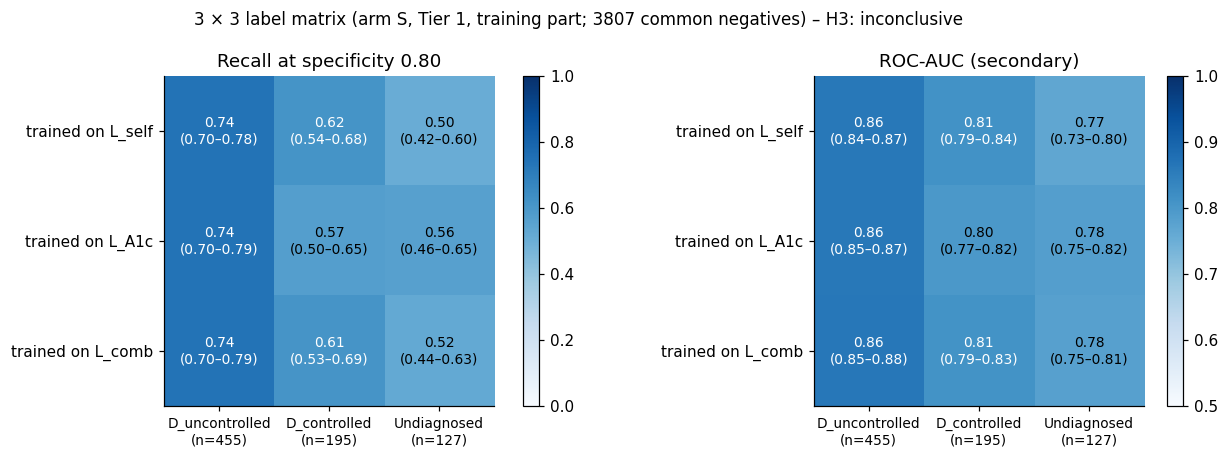

In [11]:
elem_v = {}
for el, g in H3E.groupby("element"):
    elem_v[el] = ek.combine_verdicts(g["verdict"].tolist())
h3_v = ek.combine_verdicts(list(elem_v.values()))
if H3E["reversed_ci_excl_0"].any():                       # locked falsifier
    h3_v = "refuted"
print(f"H3 element verdicts {elem_v} -> H3 {h3_v}")
cells.to_csv(OUT / "label_matrix_cells.csv", index=False)
H3E.to_csv(OUT / "h3_contrasts.csv", index=False)
S8["label_matrix"] = dict(cells=cells.round(5).to_dict("records"), recall=LM["recall"].round(5).to_dict(),
                          auc=LM["auc"].round(5).to_dict(), contrasts=H3E.round(5).to_dict("records"),
                          element_verdicts=elem_v, verdict=h3_v, row_wise_min=roww,
                          worst_gap=dict(zip(LABELS3, gaps.round(5))), strata_train=cnt.to_dict())

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1.25, 1]})
for ax, (mat, key, ttl) in zip(axes, [(LM["recall"], "recall", "Recall at specificity 0.80"), (LM["auc"], "auc", "ROC-AUC (secondary)")]):
    im = ax.imshow(mat.to_numpy(), cmap="Blues", vmin=0 if key == "recall" else 0.5, vmax=1)
    for i, lab in enumerate(LABELS3):
        for j, st in enumerate(F.POS_STRATA):
            r = cells[(cells["train_label"] == lab) & (cells["stratum"] == st)].iloc[0]
            v = mat.loc[lab, st]
            ax.text(j, i, f"{v:.2f}\n({r[key + '_lo']:.2f}–{r[key + '_hi']:.2f})", ha="center", va="center",
                    fontsize=9, color="white" if v > (0.6 if key == "recall" else 0.8) else "black")
    ax.set_xticks(range(3)); ax.set_xticklabels([f"{s}\n(n={int(cnt[s])})" for s in F.POS_STRATA], fontsize=9)
    ax.set_yticks(range(3)); ax.set_yticklabels([f"trained on {l}" for l in LABELS3])
    ax.set_title(ttl); ax.grid(False)
    fig.colorbar(im, ax=ax, fraction=0.046)
fig.suptitle(f"3 × 3 label matrix (arm S, Tier 1, training part; {int(cnt['NonDiabetic'])} common negatives) – H3: {h3_v}", fontsize=11)
fig.tight_layout()
f82 = plots.savefig(fig, "S8_label_matrix", caption="F8-2. 3x3 label matrix: arm S trained on L_self, L_A1c or L_comb "
                    "(identical folds, steps and C0) and scored on D-uncontrolled, D-controlled and Undiagnosed cases against "
                    "the common NonDiabetic negatives. Left: recall at specificity 0.80 with 95 % stratified bootstrap CI "
                    "(thresholds re-estimated per replicate); right: ROC-AUC.")
plt.show()

**So what.** Every element of the locked pattern points the predicted way, but the differences are small (at most
about 0.06) and every paired CI includes 0 while reaching beyond ±0.05, so H3 is **inconclusive**. The row-wise reading
tells the stronger story: *whatever* the training label, the Undiagnosed column is the hardest, and the AUCs agree.
Undiagnosed people lack the care traces and treatment-era profile the features pick up, so changing the label shifts
recall by only a few points. The label shapes *what the model claims to measure* (§5) more than *whom this feature set
can find*.

## 7 Access-proxy audit arm
**Why.** If the self-report label carries the access imprint of §5, a model trained on `L_self` should learn that
*lacking access lowers the chance of "having diabetes"* – an artefact of who gets diagnosed – while one trained on
HbA1c (which needs no doctor) should not. The audit arm adds **uninsured** (HIQ011 = 2) and **no usual place of care**
(HUQ030 = 2) to the arm-S pipeline and fits it on each label; per-SD coefficients are bootstrapped with the same seed
for every label, so label differences are paired. This arm is an **audit instrument only**.

In [12]:
t0 = time.time()
mk_acc = lambda: F.access_pipeline(cfgS, 1, C_=C0)
assert set(F.ACCESS_FEATURES) <= set(mk_acc()[:-1].fit(X1.iloc[:500], y[:500]).get_feature_names_out())
seed_acc = ek.derive_seed(C.SEED_MASTER, "S8", "access_audit")
CB = {lab: ek.coef_bootstrap(mk_acc, X1, YL[lab], n_boot=C.N_BOOT_COEF, seed=seed_acc, fit_params=fpS, n_jobs=N_JOBS)
      for lab in LABELS3}
sd_bin = {f: float(np.sqrt(grp[f].fillna(0).mean() * (1 - grp[f].fillna(0).mean()))) for f in F.ACCESS_FEATURES}
acc_rows = []
for f in F.ACCESS_FEATURES:
    for lab in LABELS3:
        s_ = CB[lab].summary.loc[f]
        acc_rows.append({"feature": f, "label": lab, "coef_per_sd": s_["coef"], "lo": s_["q_low"], "hi": s_["q_high"],
                         "boot_sd": s_["sd"], "OR_yes_vs_no": np.exp(s_["coef"] / sd_bin[f]),
                         "OR_lo": np.exp(s_["q_low"] / sd_bin[f]), "OR_hi": np.exp(s_["q_high"] / sd_bin[f])})
ACC = pd.DataFrame(acc_rows)
diff_rows = []
for f in F.ACCESS_FEATURES:
    for a, b in (("L_self", "L_comb"), ("L_self", "L_A1c"), ("L_comb", "L_A1c")):
        d = CB[a].coefs[f].to_numpy() - CB[b].coefs[f].to_numpy()
        e, lo, hi, se = F.summarise(CB[a].summary.loc[f, "coef"] - CB[b].summary.loc[f, "coef"], d)
        diff_rows.append({"feature": f, "contrast": f"{a} - {b}", "diff_per_sd": e, "lo": lo, "hi": hi,
                          "ci_excludes_0": bool(lo > 0 or hi < 0)})
ACCD = pd.DataFrame(diff_rows)
print(f"access audit arm: {len(LABELS3)} labels x (1 + {C.N_BOOT_COEF}) fits, {time.time() - t0:.0f} s")
show(ACC, 3)
print("\npaired differences of the per-SD coefficient between training labels:")
show(ACCD, 3)
ACC.to_csv(OUT / "access_audit_coefs.csv", index=False)
ACCD.to_csv(OUT / "access_audit_diffs.csv", index=False)
S8["access_audit"] = dict(coefs=ACC.round(5).to_dict("records"), diffs=ACCD.round(5).to_dict("records"),
                          n_boot=C.N_BOOT_COEF, sd_binary=sd_bin)

access audit arm: 3 labels x (1 + 500) fits, 28 s


feature,label,coef_per_sd,lo,hi,boot_sd,OR_yes_vs_no,OR_lo,OR_hi
uninsured,L_self,-0.112,-0.277,0.015,0.079,0.669,0.370,1.054
uninsured,L_A1c,0.016,-0.140,0.153,0.075,1.057,0.606,1.729
uninsured,L_comb,-0.012,-0.152,0.122,0.072,0.958,0.581,1.549
no_usual_place,L_self,-0.203,-0.386,-0.054,0.087,0.526,0.294,0.843
no_usual_place,L_A1c,-0.095,-0.279,0.044,0.083,0.741,0.412,1.150
no_usual_place,L_comb,-0.099,-0.259,0.025,0.073,0.731,0.440,1.081



paired differences of the per-SD coefficient between training labels:


feature,contrast,diff_per_sd,lo,hi,ci_excludes_0
uninsured,L_self - L_comb,-0.100,-0.231,0.014,False
uninsured,L_self - L_A1c,-0.128,-0.286,0.017,False
uninsured,L_comb - L_A1c,-0.028,-0.090,0.038,False
no_usual_place,L_self - L_comb,-0.104,-0.229,0.013,False
no_usual_place,L_self - L_A1c,-0.108,-0.276,0.078,False
no_usual_place,L_comb - L_A1c,-0.004,-0.076,0.090,False


**So what.** The access imprint appears where the label requires a doctor. Trained on self-report, both access features
get negative coefficients – no usual place of care *lowers* predicted risk (odds ratio about 0.5, CI excluding 0) –
although §4 showed the insured–uninsured prevalence gap is age confounding. Trained on HbA1c the coefficients are small
with CIs including 0, and the union label sits next to HbA1c. The paired self-report minus union differences (about
−0.10 per SD) have CIs that just include 0: suggestive, not established. A self-report model would **score people with
poor access as lower risk because they were never diagnosed** – a feedback loop that supports the union label and
keeping access out of the model.

## 8 Reweighing
**Why.** Reweighing (Kamiran & Calders 2012) gives each training row the weight w(g, y) = P(g)·P(y) / P(g, y), making
group and label independent in the weighted data. It is applied inside every training fold on top of arm S's survey
weights, so the comparison with S is paired. Race (pre-specified) and, as extensions, insurance and low access are
reweighed. ΔAUC uses the §7.4.1 engine; gap changes are paired bootstrap differences of EOD.

In [13]:
from joblib import parallel_config
from sklearn.metrics import roc_auc_score
from scipy import stats as sstats

def fold_auc(oof, pop="E-ALL"):
    yy, m = pop_of(pop)
    out = {}
    for (r, f), g in oof.groupby(["repeat", "fold"]):
        rows = g["row"].to_numpy()
        k = m[rows]
        out[(r, f)] = roc_auc_score(yy[rows][k], g["prob"].to_numpy()[k])
    return pd.Series(out)

def compare_auc(oof_a, oof_b, pop="E-ALL", tag=""):
    """Paired ΔAUC A - B with the S7 engine: on E-ALL the estimate is the fold-mean paired difference and the interval the
    wider of corrected t and paired bootstrap; on E-SCREEN the pooled-OOF difference with its paired bootstrap interval."""
    yy, m = pop_of(pop)
    pa, pb = ek.mean_oof(oof_a, n), ek.mean_oof(oof_b, n)
    bs = ek.paired_bootstrap(yy, pa, pb, "roc_auc", n_boot=C.N_BOOT, eval_mask=m,
                             seed=ek.derive_seed(C.SEED_MASTER, "S8", "dauc", tag, pop))
    row = dict(pop=pop, diff_pooled=bs["diff"], boot_lo=bs["ci_low"], boot_hi=bs["ci_high"])
    est, lo, hi, se, interval = bs["diff"], bs["ci_low"], bs["ci_high"], bs["se"], "bootstrap"
    mdd = (sstats.norm.ppf(0.975) + sstats.norm.ppf(0.8)) * se
    if pop == "E-ALL":
        ct = ek.corrected_t((fold_auc(oof_a) - fold_auc(oof_b)).to_numpy(), n_train_fold, n_test_fold)
        row.update(t_lo=ct["ci_low"], t_hi=ct["ci_high"])
        est = ct["mean"]
        if ct["ci_high"] - ct["ci_low"] >= hi - lo:
            lo, hi, se, interval = ct["ci_low"], ct["ci_high"], ct["se_corr"], "corrected_t"
        mdd = (sstats.t.ppf(0.975, ct["df"]) + sstats.t.ppf(0.80, ct["df"])) * se
    row.update(est=est, lo=lo, hi=hi, se=se, interval=interval, mdd=mdd)
    return row

RW_TARGET = {"race": "NH Asian", "insurance": "uninsured", "low_access": "low access"}
OOF_RW, RW_W, RW_ROWS, RW_EOD = {}, {}, [], []
t0 = time.time()
with parallel_config(max_nbytes=None):
    for attr in RW_TARGET:
        gvals = grp[attr].to_numpy(dtype=object)
        w_rw = F.reweighing_weights(gvals, y)
        RW_W[attr] = w_rw
        OOF_RW[attr] = F.cv_predict_reweighed(mk_S, X1, y, folds, gvals, base_weight=w_svy, n_jobs=N_JOBS)
print(f"reweighing arms: {len(RW_TARGET)} x {len(folds)} fits, {time.time() - t0:.0f} s")
for attr, w_rw in RW_W.items():
    lv = grp[attr].fillna("(unknown)")
    tab = pd.DataFrame({"g": lv, "y": y, "w": w_rw}).groupby(["g", "y"])["w"].first().unstack()
    print(f"\n{attr}: reweighing weights w(g, y) on the training part (range {w_rw.min():.3f}-{w_rw.max():.3f})")
    display(tab.round(3).rename(columns={0: "w(y=0)", 1: "w(y=1)"}))
    PMx = ek.mean_oof(OOF_RW[attr], n)
    for pop in ("E-ALL", "E-SCREEN"):
        r = compare_auc(OOF_RW[attr], OOF[("S", 1, "lr")], pop, tag=f"rw_{attr}")
        r.update(arm=f"S+RW({attr})", w_min=w_rw.min(), w_max=w_rw.max(),
                 verdict_auc=ek.verdict(r["lo"], r["hi"], AUC_SESOI, "+", r["est"]))
        RW_ROWS.append(r)
    point, boot, codes, mm = audit(attr, "E-ALL", 1, ("S", "RW"), preds={"RW": PMx})
    lvls = F.LEVELS[attr]
    ref = lvls.index(F.REFERENCE[attr])
    for g_i, g_nm in enumerate(lvls):
        if g_i == ref:
            continue
        eod_pt = point["tpr"][0, :, g_i] - point["tpr"][0, :, ref]
        eod_bt = boot["tpr"][:, :, g_i] - boot["tpr"][:, :, ref]
        e, lo, hi, _ = F.summarise(eod_pt[1] - eod_pt[0], eod_bt[:, 1] - eod_bt[:, 0])
        ea, alo, ahi, _ = F.summarise(abs(eod_pt[1]) - abs(eod_pt[0]), np.abs(eod_bt[:, 1]) - np.abs(eod_bt[:, 0]))
        RW_EOD.append({"arm": f"S+RW({attr})", "attribute": attr, "group": g_nm, "eod_S": eod_pt[0], "eod_RW": eod_pt[1],
                       "d_eod": e, "d_eod_lo": lo, "d_eod_hi": hi, "d_abs_eod": ea, "d_abs_lo": alo, "d_abs_hi": ahi,
                       "target": g_nm == RW_TARGET[attr]})
RWT = pd.DataFrame(RW_ROWS)
RWE = pd.DataFrame(RW_EOD)
print("\nΔAUC reweighed arm − S:")
show(RWT[["arm", "pop", "est", "lo", "hi", "interval", "mdd", "w_min", "w_max", "verdict_auc"]], 4)
print("\nchange of equal-opportunity differences (reweighed − S), E-ALL:")
show(RWE, 3)
RWT.to_csv(OUT / "reweighing_auc.csv", index=False)
RWE.to_csv(OUT / "reweighing_eod.csv", index=False)
S8["reweighing"] = dict(auc=RWT.round(5).to_dict("records"), eod=RWE.round(5).to_dict("records"),
                        weight_range={a: [float(w.min()), float(w.max())] for a, w in RW_W.items()})

reweighing arms: 3 x 25 fits, 5 s

race: reweighing weights w(g, y) on the training part (range 0.699-1.161)


y,w(y=0),w(y=1)
g,,
Mexican American,1.069,0.759
NH Asian,0.987,1.068
NH Black,1.097,0.699
NH White,0.972,1.161
Other Hispanic,1.008,0.961
Other/Multi,1.033,0.865



insurance: reweighing weights w(g, y) on the training part (range 0.949-1.356)


y,w(y=0),w(y=1)
g,,
(unknown),0.949,1.356
insured,1.004,0.979
uninsured,0.955,1.296



low_access: reweighing weights w(g, y) on the training part (range 0.678-1.677)


y,w(y=0),w(y=1)
g,,
(unknown),1.107,0.678
low access,0.924,1.677
usual access,1.016,0.928



ΔAUC reweighed arm − S:


arm,pop,est,lo,hi,interval,mdd,w_min,w_max,verdict_auc
S+RW(race),E-ALL,-0.0002,-0.0018,0.0014,corrected_t,0.0022,0.6987,1.1614,equivalent
S+RW(race),E-SCREEN,-0.0013,-0.0044,0.0020,bootstrap,0.0046,0.6987,1.1614,equivalent
S+RW(insurance),E-ALL,0.0001,-0.0005,0.0007,corrected_t,0.0009,0.9491,1.3560,equivalent
S+RW(insurance),E-SCREEN,0.0021,0.0009,0.0033,bootstrap,0.0017,0.9491,1.3560,equivalent
S+RW(low_access),E-ALL,-0.0002,-0.0017,0.0013,corrected_t,0.0021,0.6780,1.6769,equivalent
S+RW(low_access),E-SCREEN,0.0041,0.0013,0.0069,bootstrap,0.0039,0.6780,1.6769,equivalent



change of equal-opportunity differences (reweighed − S), E-ALL:


arm,attribute,group,eod_S,eod_RW,d_eod,d_eod_lo,d_eod_hi,d_abs_eod,d_abs_lo,d_abs_hi,target
S+RW(race),race,NH Black,-0.098,-0.131,-0.033,-0.086,-0.003,0.033,-0.003,0.084,False
S+RW(race),race,NH Asian,-0.184,-0.201,-0.018,-0.093,0.053,0.018,-0.053,0.093,True
S+RW(race),race,Mexican American,-0.085,-0.103,-0.018,-0.096,0.032,0.018,-0.036,0.089,False
S+RW(race),race,Other Hispanic,0.023,0.006,-0.018,-0.061,0.014,-0.018,-0.054,0.045,False
S+RW(race),race,Other/Multi,-0.077,-0.095,-0.018,-0.053,0.025,0.018,-0.030,0.050,False
S+RW(insurance),insurance,uninsured,-0.068,-0.029,0.039,-0.010,0.062,-0.039,-0.057,0.026,True
S+RW(low_access),low_access,low access,-0.094,-0.047,0.047,-0.011,0.108,-0.047,-0.102,0.049,True


**So what.** Reweighing is an instructive null. Race weights range 0.70–1.16 (NH Black cases down-weighted most), yet every ΔAUC interval lies inside ±0.01. The gaps do not close either: race reweighing leaves the NH Asian gap
where it was and *widens* the NH Black gap (CI excluding 0), because it removes the prevalence difference that made
Black cases easier to find. Insurance and low-access reweighing narrow their gaps by about 0.04–0.05 with CIs including
0. Reweighing acts on the label–group association; the gaps of §8.3 come from features and from the diagnosis
component of the label.

## 9 WHtR measurement fix (P14-b)
**Why.** §5 found that BMI under-reads adiposity in Asian adults (WHtR − BMI single-feature AUC gain +0.137 Asian vs
+0.049 White), and §8.3 found Asian cases missed most because they are leaner. Arm S+WHtR replaces waist by
waist-to-height ratio (P14, locked in §6, `prior_exposure = descriptive_seen`). Locked prediction **P14-b**: Asian TPR
rises by at least 0.05 (falsifier: upper CI bound below 0.05), with a smaller White change. With 40 Asian positives
clustered in few PSUs, a simple and a **PSU-cluster (Rao–Wu) bootstrap** are both computed; the wider decides.

In [14]:
pW = PM[("S+WHtR", 1, "lr")]
res = {}
for wt in ("simple", "psu"):
    point, boot, codes, mm = audit("race", "E-ALL", 1, ("S", "S+WHtR"), weights=wt)
    res[wt] = (point, boot)
lv = F.LEVELS["race"]
iA, iW = lv.index("NH Asian"), lv.index("NH White")
whtr_rows = []
def add_whtr(name, pt_fn):
    row = {"quantity": name}
    for wt in ("simple", "psu"):
        point, boot = res[wt]
        e, lo, hi, se = F.summarise(pt_fn(point)[0], pt_fn(boot))
        bvals = np.asarray(pt_fn(boot), float)
        row.update({"est": e, f"{wt}_lo": lo, f"{wt}_hi": hi, f"{wt}_se": se, f"{wt}_boot_mean": float(np.nanmean(bvals))})
    wide = "psu" if (row["psu_hi"] - row["psu_lo"]) >= (row["simple_hi"] - row["simple_lo"]) else "simple"
    row.update(lo=row[f"{wide}_lo"], hi=row[f"{wide}_hi"], interval=wide)
    whtr_rows.append(row)
    return row
r_tA = add_whtr("TPR NH Asian, S", lambda d: d["tpr"][:, 0, iA])
r_tA2 = add_whtr("TPR NH Asian, S+WHtR", lambda d: d["tpr"][:, 1, iA])
r_tW = add_whtr("TPR NH White, S", lambda d: d["tpr"][:, 0, iW])
r_tW2 = add_whtr("TPR NH White, S+WHtR", lambda d: d["tpr"][:, 1, iW])
r_dA = add_whtr("ΔTPR NH Asian", lambda d: d["tpr"][:, 1, iA] - d["tpr"][:, 0, iA])
r_dW = add_whtr("ΔTPR NH White", lambda d: d["tpr"][:, 1, iW] - d["tpr"][:, 0, iW])
r_dd = add_whtr("ΔTPR Asian − ΔTPR White", lambda d: (d["tpr"][:, 1, iA] - d["tpr"][:, 0, iA]) - (d["tpr"][:, 1, iW] - d["tpr"][:, 0, iW]))
r_eod = add_whtr("Δ|EOD| Asian vs White", lambda d: np.abs(d["tpr"][:, 1, iA] - d["tpr"][:, 1, iW]) - np.abs(d["tpr"][:, 0, iA] - d["tpr"][:, 0, iW]))
r_auc = add_whtr("ΔAUC overall", lambda d: d["auc_all"][:, 1] - d["auc_all"][:, 0])
r_aA = add_whtr("ΔAUC within NH Asian", lambda d: d["auc"][:, 1, iA] - d["auc"][:, 0, iA])
r_aW = add_whtr("ΔAUC within NH White", lambda d: d["auc"][:, 1, iW] - d["auc"][:, 0, iW])
r_h4 = add_whtr("ΔAUC Asian − ΔAUC White (H4b, model level)", lambda d: (d["auc"][:, 1, iA] - d["auc"][:, 0, iA]) - (d["auc"][:, 1, iW] - d["auc"][:, 0, iW]))
WH = pd.DataFrame(whtr_rows)
show(WH[["quantity", "est", "simple_lo", "simple_hi", "simple_boot_mean", "psu_lo", "psu_hi", "psu_boot_mean", "interval"]], 3)
# E-SCREEN (secondary; NH Asian has 11 positives -> suppressed, numbers only)
pt_s, bt_s, _, _ = audit("race", "E-SCREEN", 1, ("S", "S+WHtR"))
dA_s = F.summarise(pt_s["tpr"][0, 1, iA] - pt_s["tpr"][0, 0, iA], bt_s["tpr"][:, 1, iA] - bt_s["tpr"][:, 0, iA])
print(f"\nE-SCREEN (suppressed, {int(pt_s['n_pos'][0, 0, iA])} Asian positives): ΔTPR NH Asian {dA_s[0]:+.3f} ({dA_s[1]:+.3f}, {dA_s[2]:+.3f})")
p14a = next(r for r in S7m["scoreboard_detail"] if r["hyp_id"] == "P14" and r["sub"] == "(a) AUC" and r["pop"] == "E-ALL" and r["tier"] == 1)
print(f"P14-a from §7 (E-ALL, corrected t): ΔAUC {p14a['est']:+.4f} ({p14a['lo']:+.4f}, {p14a['hi']:+.4f}) -> {p14a['verdict']}")

quantity,est,simple_lo,simple_hi,simple_boot_mean,psu_lo,psu_hi,psu_boot_mean,interval
"TPR NH Asian, S",0.525,0.375,0.700,0.541,0.333,0.692,0.533,psu
"TPR NH Asian, S+WHtR",0.550,0.400,0.700,0.554,0.353,0.700,0.540,psu
"TPR NH White, S",0.709,0.651,0.766,0.711,0.649,0.776,0.709,psu
"TPR NH White, S+WHtR",0.721,0.656,0.764,0.715,0.655,0.768,0.710,psu
ΔTPR NH Asian,0.025,0.000,0.075,0.013,-0.042,0.071,0.008,psu
ΔTPR NH White,0.013,-0.020,0.030,0.004,-0.024,0.029,0.001,psu
ΔTPR Asian − ΔTPR White,0.012,-0.028,0.068,0.009,-0.033,0.067,0.006,psu
Δ|EOD| Asian vs White,-0.012,-0.068,0.030,-0.008,-0.067,0.033,-0.006,psu
ΔAUC overall,-0.001,-0.003,0.001,-0.001,-0.003,0.000,-0.001,simple
ΔAUC within NH Asian,0.003,-0.004,0.011,0.003,-0.006,0.011,0.003,psu



E-SCREEN (suppressed, 11 Asian positives): ΔTPR NH Asian +0.091 (+0.000, +0.273)
P14-a from §7 (E-ALL, corrected t): ΔAUC -0.0009 (-0.0028, +0.0009) -> supported


P14-b: ΔTPR NH Asian +0.025 (-0.042, +0.071; psu interval) -> inconclusive; White control |Δ| smaller: True
P14 overall (a: supported, b: inconclusive) -> inconclusive
H4b model level: +0.005 (-0.004, +0.013) -> inconclusive; S5 single-feature verdict supported -> H4b supported


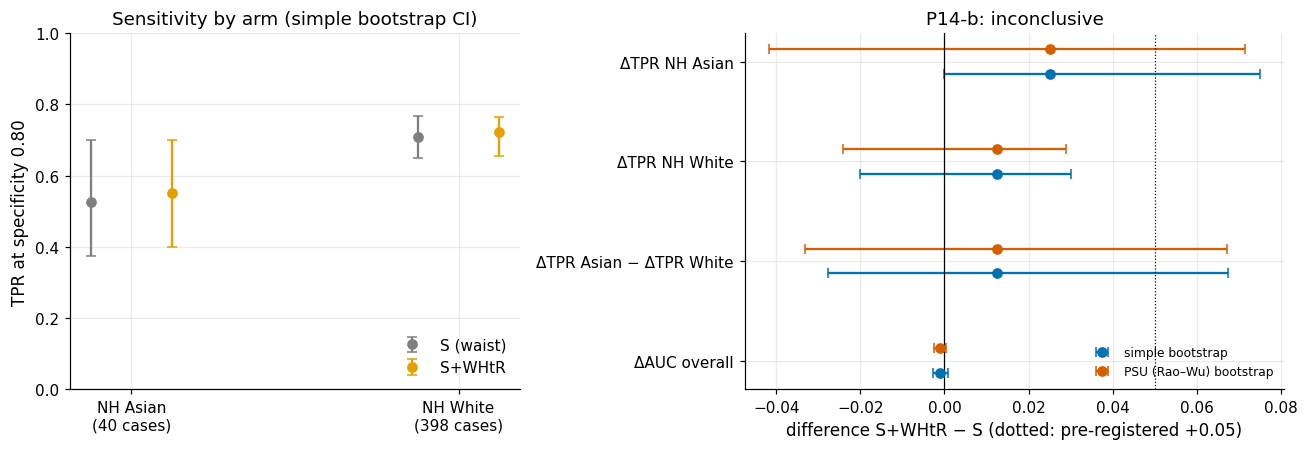

In [15]:
v_p14b = ek.verdict(r_dA["lo"], r_dA["hi"], GAP, "+", r_dA["est"])
v_p14b = "refuted" if (v_p14b == "equivalent" or r_dA["hi"] < GAP) else v_p14b     # locked falsifier
control_ok = abs(r_dW["est"]) < abs(r_dA["est"])
v_p14 = ek.combine_verdicts([p14a["verdict"], v_p14b])
v_h4b_model = ("supported" if (r_h4["lo"] > 0 and r_h4["est"] >= AUC_SESOI) else
               "refuted" if r_h4["hi"] < 0 else "inconclusive")
s5_h4b = R.load_section("S5")["hypotheses"]["H4b"]["verdict"]
v_h4b = "mixed" if (s5_h4b in ("supported", "refuted") and v_h4b_model in ("supported", "refuted") and v_h4b_model != s5_h4b) else s5_h4b
print(f"P14-b: ΔTPR NH Asian {r_dA['est']:+.3f} ({r_dA['lo']:+.3f}, {r_dA['hi']:+.3f}; {r_dA['interval']} interval) -> {v_p14b}; "
      f"White control |Δ| smaller: {control_ok}")
print(f"P14 overall (a: {p14a['verdict']}, b: {v_p14b}) -> {v_p14}")
print(f"H4b model level: {r_h4['est']:+.3f} ({r_h4['lo']:+.3f}, {r_h4['hi']:+.3f}) -> {v_h4b_model}; S5 single-feature verdict "
      f"{s5_h4b} -> H4b {v_h4b}")
WH.to_csv(OUT / "whtr_p14b.csv", index=False)
S8["whtr"] = dict(table=WH.round(5).to_dict("records"), p14b_verdict=v_p14b, p14_verdict=v_p14, white_control_smaller=control_ok,
                  p14a_from_S7={k: p14a[k] for k in ("est", "lo", "hi", "verdict")}, h4b_model_verdict=v_h4b_model,
                  h4b_s5_verdict=s5_h4b, h4b_verdict=v_h4b, escreen_dtpr_asian=list(dA_s[:3]))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1, 1.2]})
ax = axes[0]
for j, (nm, a, b) in enumerate([("NH Asian", r_tA, r_tA2), ("NH White", r_tW, r_tW2)]):
    for k_, (r_, col, lab) in enumerate([(a, C.OKABE_ITO["grey"], "S (waist)"), (b, C.OKABE_ITO["orange"], "S+WHtR")]):
        x = j + (k_ - 0.5) * 0.25
        ax.errorbar(x, r_["est"], yerr=[[r_["est"] - r_["simple_lo"]], [r_["simple_hi"] - r_["est"]]], fmt="o", color=col,
                    capsize=3, label=lab if j == 0 else None)
ax.set_xticks([0, 1]); ax.set_xticklabels([f"NH Asian\n({int(res['simple'][0]['n_pos'][0, 0, iA])} cases)",
                                            f"NH White\n({int(res['simple'][0]['n_pos'][0, 0, iW])} cases)"])
ax.set_ylabel("TPR at specificity 0.80"); ax.set_ylim(0, 1); ax.legend(loc="lower right")
ax.set_title("Sensitivity by arm (simple bootstrap CI)")
ax = axes[1]
qs = ["ΔTPR NH Asian", "ΔTPR NH White", "ΔTPR Asian − ΔTPR White", "ΔAUC overall"]
for i, q in enumerate(qs):
    r_ = WH.set_index("quantity").loc[q]
    for k_, (wt, col) in enumerate([("simple", C.OKABE_ITO["blue"]), ("psu", C.OKABE_ITO["vermillion"])]):
        ax.errorbar(r_["est"], -i + (k_ - 0.5) * 0.25, xerr=[[r_["est"] - r_[f"{wt}_lo"]], [r_[f"{wt}_hi"] - r_["est"]]],
                    fmt="o", color=col, capsize=3, label=("simple bootstrap" if wt == "simple" else "PSU (Rao–Wu) bootstrap") if i == 0 else None)
ax.axvline(0, color="black", lw=0.8); ax.axvline(GAP, color="black", lw=0.8, ls=":")
ax.set_yticks([-i for i in range(len(qs))]); ax.set_yticklabels(qs)
ax.set_xlabel("difference S+WHtR − S (dotted: pre-registered +0.05)"); ax.legend(fontsize=8, loc="lower right")
ax.set_title(f"P14-b: {v_p14b}")
fig.tight_layout()
f83 = plots.savefig(fig, "S8_whtr_asian_white", caption="F8-3. WHtR measurement fix (arm S+WHtR vs S, E-ALL, Tier 1): TPR at "
                    "specificity 0.80 for NH Asian and NH White adults (left) and the paired changes with simple stratified and "
                    "PSU-cluster (Rao-Wu) bootstrap 95 % CIs (right); dotted line = pre-registered minimum gain of 0.05.")
plt.show()

**So what.** The fix moves the right group in the right direction, but by little: NH Asian sensitivity rises by +0.025
– one more case of 40 – against +0.013 for White adults, with overall AUC unchanged (P14-a). The PSU interval runs from
about −0.04 to +0.07, so P14-b is **inconclusive**. At model level the single-feature WHtR advantage (H4b) largely
disappears: the model already contains waist, height and BMI. WHtR is not adopted as a new preparation step.

## 10 Group-specific thresholds
**Why.** A group-specific threshold (Hardt et al. 2016) is **not** implemented (DR-S8-02: it needs race at prediction
time and equalises TPR by "levelling down"); its instability with about 40 Asian cases is quantified here.

In [16]:
def asian_threshold(w=None):
    w = np.ones(n) if w is None else w
    a_pos, a_neg = (grp["race"].eq("NH Asian").to_numpy() & (y == 1)), (grp["race"].eq("NH Asian").to_numpy() & (y == 0))
    w_pos = (grp["race"].eq("NH White").to_numpy() & (y == 1))
    hit = pS >= thr_check
    tpr_w = np.average(hit[w_pos], weights=w[w_pos])
    s_ = np.sort(pS[a_pos]); ww = w[a_pos][np.argsort(pS[a_pos])]
    cum = np.cumsum(ww[::-1])[::-1] / ww.sum()          # share of Asian cases at or above each score
    k = np.flatnonzero(cum >= tpr_w - 1e-12).max()
    t_a = s_[k]
    fpr_a = np.average(pS[a_neg] >= t_a, weights=w[a_neg])
    return t_a, fpr_a, tpr_w
t_a, fpr_a, tpr_w = asian_threshold()
Wst = F.stratified_counts((grp["race"].astype(str) + "|" + pd.Series(y).astype(str)).to_numpy(), C.N_BOOT, ek.derive_seed(C.SEED_MASTER, "S8", "gthr"))
bt = np.array([asian_threshold(Wst[b])[:2] for b in range(len(Wst))])
fpr_overall_a = float(GT1.set_index(["attribute", "group"]).loc[("race", "NH Asian"), "fpr"])
GTHR = dict(threshold_overall=thr_check, threshold_asian=t_a, threshold_asian_ci=list(np.percentile(bt[:, 0], [2.5, 97.5])),
            fpr_asian_at_own=fpr_a, fpr_asian_at_own_ci=list(np.percentile(bt[:, 1], [2.5, 97.5])), fpr_asian_at_shared=fpr_overall_a,
            tpr_white=tpr_w)
print(f"shared threshold {thr_check:.3f}; Asian threshold matching the White TPR ({tpr_w:.3f}): {t_a:.3f} "
      f"(95 % CI {GTHR['threshold_asian_ci'][0]:.3f}-{GTHR['threshold_asian_ci'][1]:.3f})")
print(f"Asian FPR: {fpr_overall_a:.3f} at the shared threshold -> {fpr_a:.3f} at the group threshold "
      f"(95 % CI {GTHR['fpr_asian_at_own_ci'][0]:.3f}-{GTHR['fpr_asian_at_own_ci'][1]:.3f})")
S8["group_threshold_counterfactual"] = GTHR

shared threshold 0.638; Asian threshold matching the White TPR (0.709): 0.545 (95 % CI 0.410-0.618)
Asian FPR: 0.127 at the shared threshold -> 0.175 at the group threshold (95 % CI 0.108-0.274)


## 11 Fairness–performance trade-off
**Why.** A mitigation is worth adopting only if it narrows its target gap without costing discrimination: ΔAUC vs the
change in the target group's |TPR gap|, with a "no practical change" box of |ΔAUC| < 0.01 and |Δ gap| < 0.05.

arm,target,d_auc,d_auc_lo,d_auc_hi,d_abs_eod,d_abs_eod_lo,d_abs_eod_hi,in_no_change_box
S+RW(race),NH Asian,-0.0002,-0.0018,0.0014,0.0176,-0.0525,0.0926,False
S+RW(insurance),uninsured,0.0001,-0.0005,0.0007,-0.0392,-0.0574,0.0264,False
S+RW(low_access),low access,-0.0002,-0.0017,0.0013,-0.0471,-0.1019,0.0486,False
S+WHtR,NH Asian,-0.0009,-0.0028,0.0009,-0.0124,-0.0673,0.0332,False


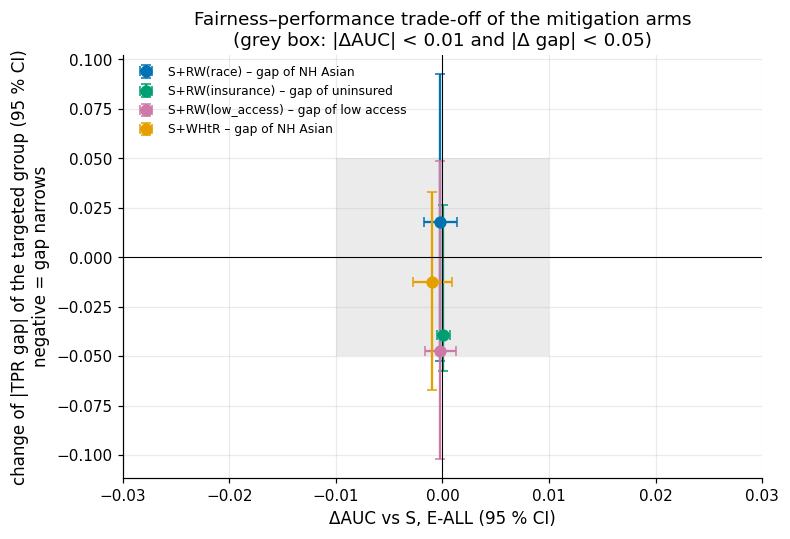

In [17]:
wh_auc = compare_auc(OOF[("S+WHtR", 1, "lr")], OOF[("S", 1, "lr")], "E-ALL", tag="whtr")
TO = []
for attr, tgt in RW_TARGET.items():
    a = RWT[(RWT["arm"] == f"S+RW({attr})") & (RWT["pop"] == "E-ALL")].iloc[0]
    e = RWE[(RWE["arm"] == f"S+RW({attr})") & (RWE["group"] == tgt)].iloc[0]
    TO.append({"arm": f"S+RW({attr})", "target": tgt, "d_auc": a["est"], "d_auc_lo": a["lo"], "d_auc_hi": a["hi"],
               "d_abs_eod": e["d_abs_eod"], "d_abs_eod_lo": e["d_abs_lo"], "d_abs_eod_hi": e["d_abs_hi"]})
TO.append({"arm": "S+WHtR", "target": "NH Asian", "d_auc": wh_auc["est"], "d_auc_lo": wh_auc["lo"], "d_auc_hi": wh_auc["hi"],
           "d_abs_eod": r_eod["est"], "d_abs_eod_lo": r_eod["lo"], "d_abs_eod_hi": r_eod["hi"]})
TO = pd.DataFrame(TO)
TO["in_no_change_box"] = (TO["d_auc_lo"] > -AUC_SESOI) & (TO["d_auc_hi"] < AUC_SESOI) & (TO["d_abs_eod_lo"] > -GAP) & (TO["d_abs_eod_hi"] < GAP)
show(TO, 4)
TO.to_csv(OUT / "tradeoff.csv", index=False)
S8["tradeoff"] = TO.round(5).to_dict("records")

fig, ax = plt.subplots(figsize=(7.5, 5))
ax.add_patch(plt.Rectangle((-AUC_SESOI, -GAP), 2 * AUC_SESOI, 2 * GAP, color=C.OKABE_ITO["grey"], alpha=0.15, lw=0))
cols = [C.OKABE_ITO["blue"], C.OKABE_ITO["green"], C.OKABE_ITO["purple"], C.OKABE_ITO["orange"]]
for (_, r), col in zip(TO.iterrows(), cols):
    ax.errorbar(r["d_auc"], r["d_abs_eod"], xerr=[[r["d_auc"] - r["d_auc_lo"]], [r["d_auc_hi"] - r["d_auc"]]],
                yerr=[[r["d_abs_eod"] - r["d_abs_eod_lo"]], [r["d_abs_eod_hi"] - r["d_abs_eod"]]], fmt="o", color=col,
                capsize=3, ms=7, label=f"{r['arm']} – gap of {r['target']}")
ax.axhline(0, color="black", lw=0.7); ax.axvline(0, color="black", lw=0.7)
ax.set_xlabel("ΔAUC vs S, E-ALL (95 % CI)")
ax.set_ylabel("change of |TPR gap| of the targeted group (95 % CI)\nnegative = gap narrows")
ax.set_xlim(-0.03, 0.03)
ax.legend(fontsize=8, loc="upper left")
ax.set_title("Fairness–performance trade-off of the mitigation arms\n(grey box: |ΔAUC| < 0.01 and |Δ gap| < 0.05)")
f85 = plots.savefig(fig, "S8_tradeoff", caption="F8-5. Fairness-performance plane for the mitigation arms (Tier 1): ΔAUC "
                    "against arm S on E-ALL (wider of corrected-t and paired-bootstrap CI) versus the change in the absolute "
                    "TPR gap of the targeted group at specificity 0.80 (paired stratified bootstrap); grey box = no practical change.")
plt.show()

**So what – screening audit and mitigation nulls (§8.4, §8.5, §8.10, §8.11).** On E-SCREEN only the sex contrast is
reportable: undiagnosed women are found less often than men (EOD about −0.17, CI includes 0, permutation p about
0.09); race gaps rest on 11–24 positives ("not measurable", not "fair"). Tier 2 lipids move every gap by less than its
CI. An Asian-specific threshold matching the White TPR would raise Asian false positives by about 40 % and is itself
unstable. All four mitigations cost no AUC, and none demonstrably helps (gap changes −0.05 to +0.02, intervals wider
than ±0.05): "cheap, harmless, not shown to help".

## 12 Within-group calibration
**Why.** Calibration within groups (a predicted 20 % meaning 20 % in every group) is a second fairness criterion that
cannot in general hold together with equal sensitivity when prevalences differ (Chouldechova 2017). Arm S is
class-weighted, so absolute calibration is checked on **S−B6a**, its AUC-equivalent sibling without class weights: O:E
(group-stratified bootstrap, so the number of cases varies), calibration-in-the-large (CITL) and slope.

S-B6a overall: O:E 1.017, CITL +0.027, slope 0.979


attribute,group,n,n_pos,mean_pred,observed,oe,oe_lo,oe_hi,citl,slope,oe_S_relative,oe_ci_excludes_1
race,NH White,2727,398,0.167,0.146,0.876,0.809,0.950,-0.203,1.043,0.857,True
race,NH Black,540,131,0.186,0.243,1.304,1.125,1.476,0.455,0.788,1.308,True
race,NH Asian,252,40,0.117,0.159,1.353,1.030,1.738,0.450,1.019,1.198,True
race,Mexican American,309,69,0.160,0.223,1.393,1.156,1.672,0.566,0.994,1.376,True
race,Other Hispanic,465,82,0.166,0.176,1.064,0.890,1.221,0.101,1.107,1.054,False
race,Other/Multi,291,57,0.181,0.196,1.081,0.862,1.303,0.133,0.909,1.114,False
insurance,insured,4186,725,0.170,0.173,1.018,0.958,1.076,0.029,0.983,1.007,False
insurance,uninsured,390,51,0.131,0.131,0.999,0.768,1.229,-0.001,0.902,0.907,False
low_access,usual access,3838,701,0.178,0.183,1.026,0.967,1.086,0.042,0.966,1.025,False
low_access,low access,742,75,0.108,0.101,0.935,0.750,1.113,-0.098,1.015,0.810,False


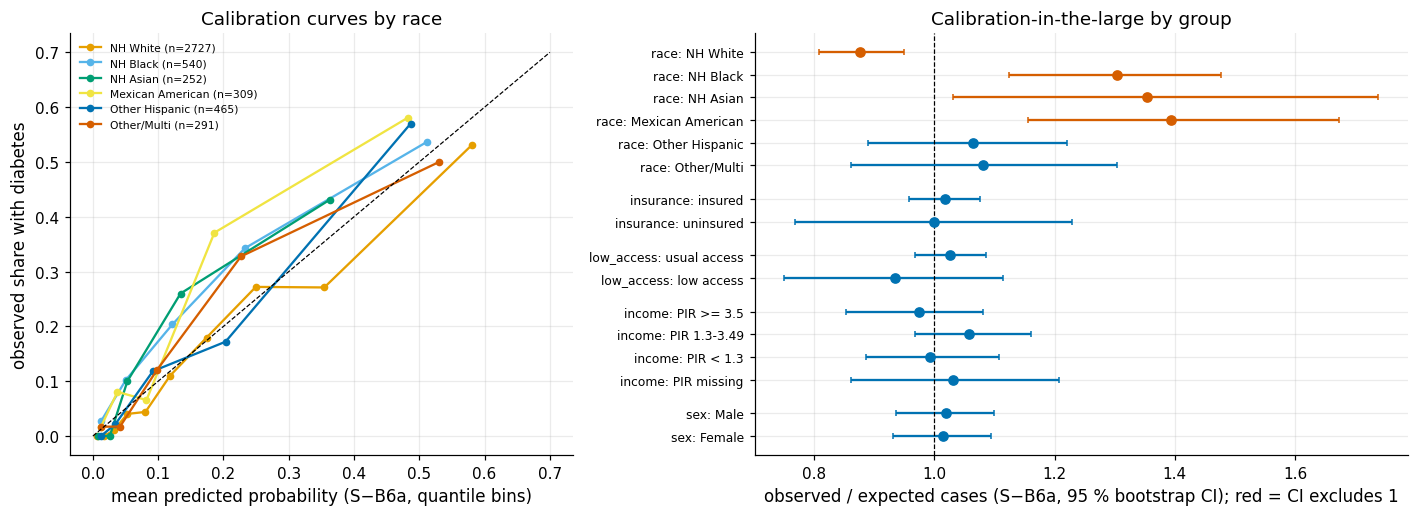

In [18]:
pC = PM[("S-B6a", 1, "lr")]
cal_rows = []
for attr in F.ATTRIBUTES:
    point, boot, codes, mm = audit(attr, "E-ALL", 1, ("S-B6a", "S"), weights="group")
    lvls = F.LEVELS[attr]
    oe_all_S = y.sum() / pS.sum()
    for g_i, g_nm in enumerate(lvls):
        m = grp[attr].eq(g_nm).to_numpy()
        slope, icpt, citl = ek._calibration(y[m], pC[m])
        e, lo, hi, _ = F.summarise(point["oe"][0, 0, g_i], boot["oe"][:, 0, g_i])
        cal_rows.append({"attribute": attr, "group": g_nm, "n": int(m.sum()), "n_pos": int(y[m].sum()),
                         "mean_pred": pC[m].mean(), "observed": y[m].mean(), "oe": e, "oe_lo": lo, "oe_hi": hi,
                         "citl": citl, "slope": slope, "oe_S_relative": point["oe"][0, 1, g_i] / oe_all_S})
CAL = pd.DataFrame(cal_rows)
CAL["oe_ci_excludes_1"] = (CAL["oe_lo"] > 1) | (CAL["oe_hi"] < 1)
slope_all, _, citl_all = ek._calibration(y, pC)
print(f"S-B6a overall: O:E {y.sum() / pC.sum():.3f}, CITL {citl_all:+.3f}, slope {slope_all:.3f}")
show(CAL, 3)
CAL.to_csv(OUT / "group_calibration.csv", index=False)
S8["calibration"] = dict(table=CAL.round(5).to_dict("records"), overall=dict(oe=float(y.sum() / pC.sum()), citl=citl_all, slope=slope_all),
                         groups_oe_ci_excl_1=CAL.loc[CAL["oe_ci_excludes_1"], ["attribute", "group", "oe"]].round(3).to_dict("records"))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1, 1.3]})
ax = axes[0]
for g_nm, col in zip(F.LEVELS["race"], plots.PALETTE):
    m = grp["race"].eq(g_nm).to_numpy()
    nb = 5 if m.sum() < 600 else 10
    q = pd.qcut(pC[m], nb, labels=False, duplicates="drop")
    d_ = pd.DataFrame({"p": pC[m], "y": y[m], "q": q}).groupby("q").mean()
    ax.plot(d_["p"], d_["y"], "o-", color=col, label=f"{g_nm} (n={int(m.sum())})", ms=4)
ax.plot([0, 0.7], [0, 0.7], color="black", lw=0.8, ls="--")
ax.set_xlabel("mean predicted probability (S−B6a, quantile bins)"); ax.set_ylabel("observed share with diabetes")
ax.set_title("Calibration curves by race"); ax.legend(fontsize=7)
ax = axes[1]
k = 0; yt, yl = [], []
for attr in F.ATTRIBUTES:
    for _, r in CAL[CAL["attribute"] == attr].iterrows():
        ax.errorbar(r["oe"], -k, xerr=[[r["oe"] - r["oe_lo"]], [r["oe_hi"] - r["oe"]]], fmt="o",
                    color=C.OKABE_ITO["vermillion"] if r["oe_ci_excludes_1"] else C.OKABE_ITO["blue"], capsize=2)
        yt.append(-k); yl.append(f"{attr}: {r['group']}"); k += 1
    k += 0.5
ax.axvline(1, color="black", lw=0.8, ls="--")
ax.set_yticks(yt); ax.set_yticklabels(yl, fontsize=8)
ax.set_xlabel("observed / expected cases (S−B6a, 95 % bootstrap CI); red = CI excludes 1")
ax.set_title("Calibration-in-the-large by group")
fig.tight_layout()
f84 = plots.savefig(fig, "S8_group_calibration", caption="F8-4. Within-group calibration of arm S-B6a (arm S without class "
                    "weights, AUC-equivalent): calibration curves by race (quantile bins) and observed/expected ratio by audit "
                    "group with stratified bootstrap 95 % CI (E-ALL, Tier 1, training part OOF).")
plt.show()

**So what.** S−B6a is well calibrated overall (O:E about 1.02, slope about 0.98) and across insurance, access, income and
sex, but **not across race**: it under-predicts for NH Black, NH Asian (O:E about 1.35) and Mexican American adults
(CIs excluding 1) and over-predicts for NH White adults. A race-blind score averages over groups whose prevalence
differs at the same feature values – the second face of the Asian TPR gap. Correcting it would need race as an input
or race-specific recalibration, excluded for the reasons of §8.10; it is a limitation for any individual use.

## 13 Verdicts
**Why.** Each locked hypothesis tested here gets one verdict from its locked rule (`evalkit.verdict` with the SESOI
of `config.SESOI`, sub-claims combined by `evalkit.combine_verdicts`). H3 is a genuine pre-registration; P14-b and H4b
were written after a descriptive look. The gap flags of §8.3–§8.4 are audit findings, listed separately.

In [19]:
sub_eall = ET1[ET1["substantive"] & ET1["verdict_status"].eq("reportable")]
sub_escr = ETs[ETs["substantive"] & ETs["verdict_status"].eq("reportable")]
SB8 = pd.DataFrame([
    dict(hyp_id="H3", prior_exposure="none", sub="E1 L_self misses Undiagnosed most", verdict=elem_v["E1"],
         evidence="; ".join(f"{r.contrast} {r.est:+.3f} ({r.lo:+.3f}, {r.hi:+.3f})" for r in H3E[H3E.element == "E1"].itertuples())),
    dict(hyp_id="H3", prior_exposure="none", sub="E2 L_A1c misses D_controlled most", verdict=elem_v["E2"],
         evidence="; ".join(f"{r.contrast} {r.est:+.3f} ({r.lo:+.3f}, {r.hi:+.3f})" for r in H3E[H3E.element == "E2"].itertuples())),
    dict(hyp_id="H3", prior_exposure="none", sub="E3 L_comb smallest worst-cell gap", verdict=elem_v["E3"],
         evidence="; ".join(f"{r.contrast} {r.est:+.3f} ({r.lo:+.3f}, {r.hi:+.3f})" for r in H3E[H3E.element == "E3"].itertuples())),
    dict(hyp_id="H3", prior_exposure="none", sub="overall", verdict=h3_v, evidence="combine_verdicts(E1-E3); falsifier: any contrast reversed with CI excluding 0"),
    dict(hyp_id="P14", prior_exposure="descriptive_seen", sub="(a) |ΔAUC| < 0.01 (from S7)", verdict=p14a["verdict"],
         evidence=f"ΔAUC {p14a['est']:+.4f} ({p14a['lo']:+.4f}, {p14a['hi']:+.4f}), corrected t"),
    dict(hyp_id="P14", prior_exposure="descriptive_seen", sub="(b) NH Asian ΔTPR ≥ +0.05", verdict=v_p14b,
         evidence=f"ΔTPR {r_dA['est']:+.3f} ({r_dA['lo']:+.3f}, {r_dA['hi']:+.3f}), {r_dA['interval']} interval; White ΔTPR {r_dW['est']:+.3f}"),
    dict(hyp_id="P14", prior_exposure="descriptive_seen", sub="overall", verdict=v_p14, evidence="combine_verdicts(a, b)"),
    dict(hyp_id="H4b", prior_exposure="descriptive_seen", sub="single feature (S5)", verdict=s5_h4b,
         evidence=R.load_section("S5")["hypotheses"]["H4b"]["estimate"]),
    dict(hyp_id="H4b", prior_exposure="descriptive_seen", sub="model level (S8, secondary)", verdict=v_h4b_model,
         evidence=f"ΔAUC_Asian − ΔAUC_White {r_h4['est']:+.4f} ({r_h4['lo']:+.4f}, {r_h4['hi']:+.4f})"),
    dict(hyp_id="H4b", prior_exposure="descriptive_seen", sub="overall", verdict=v_h4b,
         evidence="S5 primary; a decisive contradicting S8 model-level verdict would make it mixed"),
])
assert set(SB8["verdict"]) <= set(C.VERDICTS)
show(SB8)
print("\naudit flags (not hypotheses): substantive reportable gaps")
for nm_, d_ in (("E-ALL", sub_eall), ("E-SCREEN", sub_escr)):
    print(f"  {nm_}: " + ("; ".join(f"{r.attribute} {r.group} {r.eod:+.3f} [{r.eod_lo:+.3f}, {r.eod_hi:+.3f}]" for r in d_.itertuples()) or "none"))
SB8.to_csv(OUT / "scoreboard.csv", index=False)
S8["scoreboard"] = {h: g.set_index("sub")["verdict"].to_dict() for h, g in SB8.groupby("hyp_id")}
S8["verdicts"] = {"H3": h3_v, "P14": v_p14, "P14b": v_p14b, "H4b": v_h4b, "H4b_model_level": v_h4b_model}
S8["substantive_gaps"] = {"E-ALL": sub_eall[["attribute", "group", "eod", "eod_lo", "eod_hi"]].round(4).to_dict("records"),
                          "E-SCREEN": sub_escr[["attribute", "group", "eod", "eod_lo", "eod_hi"]].round(4).to_dict("records")}

hyp_id,prior_exposure,sub,verdict,evidence
H3,none,E1 L_self misses Undiagnosed most,inconclusive,"Undiagnosed: L_self - L_A1c -0.055 (-0.126, +0.024); Undiagnosed: L_self - L_comb -0.016 (-0.079, +0.024)"
H3,none,E2 L_A1c misses D_controlled most,inconclusive,"D_controlled: L_A1c - L_self -0.046 (-0.097, +0.005); D_controlled: L_A1c - L_comb -0.041 (-0.092, +0.010)"
H3,none,E3 L_comb smallest worst-cell gap,inconclusive,"worst-cell gap: L_comb - L_self -0.016 (-0.079, +0.028); worst-cell gap: L_comb - L_A1c -0.007 (-0.087, +0.059)"
H3,none,overall,inconclusive,combine_verdicts(E1-E3); falsifier: any contrast reversed with CI excluding 0
P14,descriptive_seen,(a) |ΔAUC| < 0.01 (from S7),supported,"ΔAUC -0.0009 (-0.0028, +0.0009), corrected t"
P14,descriptive_seen,(b) NH Asian ΔTPR ≥ +0.05,inconclusive,"ΔTPR +0.025 (-0.042, +0.071), psu interval; White ΔTPR +0.013"
P14,descriptive_seen,overall,inconclusive,"combine_verdicts(a, b)"
H4b,descriptive_seen,single feature (S5),supported,"WHtR - BMI gain Asian +0.137 (0.093, 0.181) vs White +0.049 (0.039, 0.058); difference CI (person +0.044, +0.135; PSU +0.035, +0.116)"
H4b,descriptive_seen,"model level (S8, secondary)",inconclusive,"ΔAUC_Asian − ΔAUC_White +0.0051 (-0.0037, +0.0134)"
H4b,descriptive_seen,overall,supported,S5 primary; a decisive contradicting S8 model-level verdict would make it mixed



audit flags (not hypotheses): substantive reportable gaps
  E-ALL: race NH Asian -0.184 [-0.343, -0.014]; income PIR < 1.3 +0.186 [+0.085, +0.270]
  E-SCREEN: none


**So what.** No fairness experiment produces a decisive verdict, and each "inconclusive" is specific: **H3** – all
three orderings point the right way, but the label shifts recall by at most about 0.06 against CIs about ±0.07 wide;
**P14** – WHtR is harmless (a) and moves Asian sensitivity the predicted way, but its +0.025 neither confirms nor
excludes +0.05 (b); **H4b** – the single-feature WHtR advantage (§5, supported) does not transfer to the model. The
decisive results are audit findings: a substantive NH Asian sensitivity gap beyond the permutation null
(exploratory), SES-driven income gaps, an access imprint under self-report, and race-level miscalibration of a
race-blind model. A FAST re-run can move the borderline audit items across their thresholds.

## 14 Outputs
**Why.** Every decision goes into the §8 decision register with evidence computed above (no value typed by hand), and
every number into `results/metrics_S8.json` and `results/S8/`, from which §10 and the slides read.

In [20]:
REGISTER_COLS = ["dr_id", "stage", "date", "type", "finding", "evidence_ref", "evidence_value", "decision",
                 "alternatives_rejected", "hyp_id", "status", "check_verdict", "check_note", "loop_ref", "change_request", "commit"]
TODAY = "2026-10-11"
eodA = ET1.set_index(["attribute", "group"]).loc[("race", "NH Asian")]
permr = PERM1.set_index("attribute")
rw_rng = {a: f"{w.min():.2f}-{w.max():.2f}" for a, w in RW_W.items()}
rw_auc = RWT[RWT["pop"] == "E-ALL"].set_index("arm")
cal_race = CAL[(CAL["attribute"] == "race") & CAL["oe_ci_excludes_1"]]
acc_d = ACCD.set_index(["feature", "contrast"])
sex_s = ETs.set_index("attribute").loc["sex"]
reg = [
    dict(dr_id="DR-S8-01", type="audit_design",
         finding="Group cells are small (no oversampling in 2021-23); E-SCREEN has 127 positives in the training part",
         evidence_ref="results/S8/group_sizes.csv", evidence_value=f"suppressed groups E-ALL {n_supp['eall']}/16, E-SCREEN {n_supp['escreen']}/16; NH Asian 40 positives (E-ALL)",
         decision="Audit race (NH Asian separate, exploratory), insurance, low access, income band, sex on training-part OOF; NCHS rule n<30 or positives<30 -> show, no gap verdict",
         alternatives_rejected="Pooling Asian with Other/Multi (hides the BMI measurement issue); verdicts on suppressed cells",
         status="decided", check_verdict="PASS", check_note="counts recomputed from the cohort and the stored split"),
    dict(dr_id="DR-S8-02", type="threshold",
         finding="One operating point is needed to compare groups; group thresholds need race at prediction time",
         evidence_ref="§8.2 and §8.10; results/metrics_S8.json group_threshold_counterfactual",
         evidence_value=f"shared threshold {thr_check:.3f} (spec 0.80, E-ALL); Asian threshold for White TPR {t_a:.3f} (CI {GTHR['threshold_asian_ci'][0]:.3f}-{GTHR['threshold_asian_ci'][1]:.3f}), Asian FPR {fpr_overall_a:.3f}->{fpr_a:.3f}",
         decision="Single threshold at overall specificity 0.80, re-estimated in each bootstrap replicate; no group-specific thresholds (race would be needed at prediction time)",
         alternatives_rejected="ThresholdOptimizer / equalised-odds post-processing (uses race at prediction, levelling down, unstable with ~40 cases)",
         status="decided", check_verdict="PASS", check_note="engine threshold equals evalkit.recall_at_specificity (asserted)"),
    dict(dr_id="DR-S8-03", type="finding",
         finding="Model reproduces label and measurement bias: NH Asian and income gaps exceed the permutation null on E-ALL",
         evidence_ref="results/S8/eod_eall_t1.csv; results/S8/permutation.csv; results/S8/gap_decomposition.csv; figures/S8_group_tpr.png",
         evidence_value=f"NH Asian EOD {eodA['eod']:+.3f} ({eodA['eod_lo']:+.3f}, {eodA['eod_hi']:+.3f}), race max|EOD| p {permr.loc['race', 'p_value']:.3f}; income p {permr.loc['income', 'p_value']:.3f}; TPR diagnosed {tpr_dx_all:.2f} vs undiagnosed {tpr_ud_all:.2f}",
         decision="Report gaps with CIs and permutation baseline; attribute them to routes (diagnosis/care traces, BMI, SES inputs); ecological-fallacy caveat; no claim about individual risk",
         alternatives_rejected="Reporting raw group differences without a null; interpreting group TPR as individual risk",
         hyp_id="", status="decided", check_verdict="PASS", check_note="NH Asian exploratory (40 positives)"),
    dict(dr_id="DR-S8-04", type="finding",
         finding="Screening-population (E-SCREEN) fairness cannot be audited by race, insurance or access at this sample size",
         evidence_ref="results/S8/eod_escreen_t1.csv",
         evidence_value=f"reportable E-SCREEN contrasts {len(rep_s)}/{len(ETs)}; female - male EOD {sex_s['eod']:+.3f} ({sex_s['eod_lo']:+.3f}, {sex_s['eod_hi']:+.3f}), permutation p {PERMs.set_index('attribute').loc['sex', 'p_value']:.3f}",
         decision="E-SCREEN group gaps shown as numbers only; the only reportable contrast (sex) reported with CI and permutation p; limitation for S10",
         alternatives_rejected="Pooling E-ALL and E-SCREEN (mixes the use cases)", status="decided", check_verdict="PASS"),
    dict(dr_id="DR-S8-05", type="hypothesis_test",
         finding="3x3 label matrix: predicted ordering points the right way but differences are small; Undiagnosed is hardest for every label",
         evidence_ref="results/S8/label_matrix_cells.csv; results/S8/h3_contrasts.csv; figures/S8_label_matrix.png",
         evidence_value=f"recall Undiagnosed L_self {LM['recall'].loc['L_self', 'Undiagnosed']:.3f}, L_A1c {LM['recall'].loc['L_A1c', 'Undiagnosed']:.3f}, L_comb {LM['recall'].loc['L_comb', 'Undiagnosed']:.3f}; D_controlled L_A1c {LM['recall'].loc['L_A1c', 'D_controlled']:.3f}; elements {elem_v}",
         decision=f"H3 verdict {h3_v}; L_comb stays the frozen target", alternatives_rejected="Switching the training label after seeing the matrix",
         hyp_id="H3", status="decided", check_verdict="PASS", check_note="L_comb x Undiagnosed cell equals E-SCREEN recall of S (asserted)"),
    dict(dr_id="DR-S8-06", type="audit",
         finding="Trained on self-report, the model learns that poor access means lower risk; the label contrast points the same way",
         evidence_ref="results/S8/access_audit_coefs.csv; results/S8/access_audit_diffs.csv",
         evidence_value=f"no usual place under L_self {ACC.set_index(['feature', 'label']).loc[('no_usual_place', 'L_self'), 'coef_per_sd']:+.3f} ({ACC.set_index(['feature', 'label']).loc[('no_usual_place', 'L_self'), 'lo']:+.3f}, {ACC.set_index(['feature', 'label']).loc[('no_usual_place', 'L_self'), 'hi']:+.3f}); uninsured L_self - L_comb {acc_d.loc[('uninsured', 'L_self - L_comb'), 'diff_per_sd']:+.3f} ({acc_d.loc[('uninsured', 'L_self - L_comb'), 'lo']:+.3f}, {acc_d.loc[('uninsured', 'L_self - L_comb'), 'hi']:+.3f}); no usual place {acc_d.loc[('no_usual_place', 'L_self - L_comb'), 'diff_per_sd']:+.3f} ({acc_d.loc[('no_usual_place', 'L_self - L_comb'), 'lo']:+.3f}, {acc_d.loc[('no_usual_place', 'L_self - L_comb'), 'hi']:+.3f})",
         decision="Access features remain audit-only (P03); evidence supports the union label over self-report",
         alternatives_rejected="Adding insurance/usual place as predictors (would encode access to diagnosis)", status="decided", check_verdict="PASS"),
    dict(dr_id="DR-S8-07", type="mitigation",
         finding="Race reweighing changes neither AUC nor the Asian gap and widens the NH Black gap",
         evidence_ref="results/S8/reweighing_auc.csv; results/S8/reweighing_eod.csv",
         evidence_value=f"w range race {rw_rng['race']}; dAUC {rw_auc.loc['S+RW(race)', 'est']:+.4f} ({rw_auc.loc['S+RW(race)', 'lo']:+.4f}, {rw_auc.loc['S+RW(race)', 'hi']:+.4f})",
         decision="Not adopted; reported as a null mitigation", alternatives_rejected="Race as a model feature (S9 sensitivity only)",
         status="decided", check_verdict="PASS"),
    dict(dr_id="DR-S8-08", type="mitigation",
         finding="Insurance and low-access reweighing: AUC unchanged, targeted gaps narrow slightly with CIs including 0",
         evidence_ref="results/S8/reweighing_auc.csv; results/S8/reweighing_eod.csv; results/S8/tradeoff.csv",
         evidence_value=f"w range insurance {rw_rng['insurance']}, low access {rw_rng['low_access']}; dAUC {rw_auc.loc['S+RW(insurance)', 'est']:+.4f} / {rw_auc.loc['S+RW(low_access)', 'est']:+.4f}",
         decision="Not adopted (no demonstrated benefit); extension item complete", alternatives_rejected="Adopting on point estimates",
         status="decided", check_verdict="PASS"),
    dict(dr_id="DR-S8-09", type="hypothesis_test",
         finding="WHtR raises NH Asian TPR in point estimate only; PSU-cluster interval crosses 0",
         evidence_ref="results/S8/whtr_p14b.csv; figures/S8_whtr_asian_white.png",
         evidence_value=f"Asian dTPR {r_dA['est']:+.3f} (simple {r_dA['simple_lo']:+.3f}, {r_dA['simple_hi']:+.3f}; PSU {r_dA['psu_lo']:+.3f}, {r_dA['psu_hi']:+.3f}); White {r_dW['est']:+.3f}; dAUC {r_auc['est']:+.4f}",
         decision=f"P14-b {v_p14b}, P14 {v_p14}; WHtR not adopted as a new preparation step; no return to the §6 design",
         alternatives_rejected="Adopting WHtR on the point estimate (post hoc)", hyp_id="P14", status="decided", check_verdict="PASS"),
    dict(dr_id="DR-S8-10", type="hypothesis_test",
         finding="The single-feature WHtR advantage for Asian adults does not transfer to the multivariable model",
         evidence_ref="results/S8/whtr_p14b.csv", evidence_value=f"model-level dAUC Asian - White {r_h4['est']:+.4f} ({r_h4['lo']:+.4f}, {r_h4['hi']:+.4f})",
         decision=f"H4b stays {v_h4b} on the S5 single-feature test; S8 model-level result {v_h4b_model} reported as secondary",
         hyp_id="H4b", status="decided", check_verdict="PASS"),
    dict(dr_id="DR-S8-11", type="finding",
         finding="Race-blind model is calibrated overall but not within race",
         evidence_ref="results/S8/group_calibration.csv; figures/S8_group_calibration.png",
         evidence_value=f"S-B6a O:E overall {y.sum() / pC.sum():.2f}; groups with CI excluding 1: {cal_race[['group', 'oe']].round(2).to_dict('records')}",
         decision="Reported as a limitation; no race-specific recalibration (same reasons as DR-S8-02)",
         alternatives_rejected="Race-specific recalibration", status="decided", check_verdict="PASS"),
    dict(dr_id="DR-S8-12", type="tradeoff",
         finding="No mitigation arm narrows its targeted gap demonstrably; none costs AUC",
         evidence_ref="results/S8/tradeoff.csv; figures/S8_tradeoff.png",
         evidence_value="; ".join(f"{r.arm}: dAUC {r.d_auc:+.4f} [{r.d_auc_lo:+.4f}, {r.d_auc_hi:+.4f}], d|gap| {r.d_abs_eod:+.3f} [{r.d_abs_eod_lo:+.3f}, {r.d_abs_eod_hi:+.3f}]" for r in TO.itertuples()),
         decision="No mitigation adopted; reported as 'cheap, harmless, not shown to help'", alternatives_rejected="Adopting the arm with the best point estimate",
         status="decided", check_verdict="PASS"),
]
REG8 = pd.DataFrame(reg)
REG8["stage"], REG8["date"] = "S8", TODAY
for c in REGISTER_COLS:
    if c not in REG8:
        REG8[c] = ""
REG8 = REG8[REGISTER_COLS].fillna("")
REG8.to_csv(C.GOVERNANCE_DIR / "register" / "S8.csv", index=False, lineterminator="\n")
show(REG8[["dr_id", "type", "decision"]])

dr_id,type,decision
DR-S8-01,audit_design,"Audit race (NH Asian separate, exploratory), insurance, low access, income band, sex on training-part OOF; NCHS rule n<30 or positives<30 -> show, no gap verdict"
DR-S8-02,threshold,"Single threshold at overall specificity 0.80, re-estimated in each bootstrap replicate; no group-specific thresholds (race would be needed at prediction time)"
DR-S8-03,finding,"Report gaps with CIs and permutation baseline; attribute them to routes (diagnosis/care traces, BMI, SES inputs); ecological-fallacy caveat; no claim about individual risk"
DR-S8-04,finding,E-SCREEN group gaps shown as numbers only; the only reportable contrast (sex) reported with CI and permutation p; limitation for S10
DR-S8-05,hypothesis_test,H3 verdict inconclusive; L_comb stays the frozen target
DR-S8-06,audit,Access features remain audit-only (P03); evidence supports the union label over self-report
DR-S8-07,mitigation,Not adopted; reported as a null mitigation
DR-S8-08,mitigation,Not adopted (no demonstrated benefit); extension item complete
DR-S8-09,hypothesis_test,"P14-b inconclusive, P14 inconclusive; WHtR not adopted as a new preparation step; no return to the §6 design"
DR-S8-10,hypothesis_test,H4b stays supported on the S5 single-feature test; S8 model-level result inconclusive reported as secondary


In [21]:
for nm, df_ in {"group_metrics_eall_t1": GT1, "eod_eall_t1": ET1, "group_metrics_escreen_t1": GTs, "eod_escreen_t1": ETs,
                "group_metrics_eall_t2": GT2, "eod_eall_t2": ET2,
                "permutation": pd.concat([PERM1, PERMs, PERM2], ignore_index=True)}.items():
    df_.to_csv(OUT / f"{nm}.csv", index=False)
S8["figures"] = [f81, f81b, f82, f83, f84, f85]
S8["runtime_seconds"] = time.time() - T_START
R.save_section("S8", S8)
print(f"saved results/metrics_S8.json, {len(list(OUT.glob('*.csv')))} tables in results/S8, governance/register/S8.csv "
      f"({len(REG8)} rows); runtime {S8['runtime_seconds']:.0f} s ({C.NB_MODE})")
print(json.dumps(S8["verdicts"]))

saved results/metrics_S8.json, 19 tables in results/S8, governance/register/S8.csv (12 rows); runtime 55 s (FINAL)
{"H3": "inconclusive", "P14": "inconclusive", "P14b": "inconclusive", "H4b": "supported", "H4b_model_level": "inconclusive"}
